# Task 1 — Introductory Track: Stabilizing and Preparing a Cat Qubit

This notebook builds the cat qubit one ingredient at a time:

| Section | What we do |
|---|---|
| **1.0** | Single-mode warm-ups: (a) single-photon loss, (b) pure two-photon loss, (c) two-photon stabilization (effective model) |
| **1.1** | Full two-mode (memory + buffer) model: inflating a cat from vacuum, truncation monitoring, Wigner snapshots |
| **1.2** | Semiclassical check $\alpha^2=\epsilon_d/g_2$ and a convergence study in $N_a$, $N_b$ |
| **1.3** | Which state is actually prepared ($|\mathcal C_+\rangle$) and how to prepare $|0_L\rangle=|+\alpha\rangle$ instead |

**Conventions** (README §0.5): $\hbar=1$, time in $\mu$s, rates in rad/$\mu$s, so a frequency $f$ quoted in MHz becomes `2*jnp.pi*f`.
Every markdown cell titled **"Theory"** gives the derivation behind the next code cell, and every cell titled **"Results"** explains what the output shows and whether it matches the "What you should see" box.

Companion files:
- `task1_issues_log.md`: everything that did not work, or behaved unexpectedly, and how we resolved it.
- `research_state_preparation.md`: a literature survey of state preparation and its physical limits, used for Task 1.3(b,c).

The first code cell below is the **starter code from the README**, kept unchanged for reference.

In [1]:
import dynamiqs as dq
import jax.numpy as jnp

dq.set_precision('double')         # see Section 0.5
Na, Nb = 24, 6
a, b = dq.destroy(Na, Nb)          # a acts on the memory, b on the buffer
g2      = 2 * jnp.pi * 0.763       # rad/us
kappa_b = 2 * jnp.pi * 2.6         # rad/us
kappa_a = 2 * jnp.pi * 9.3e-3      # rad/us
alpha   = 2.1
eps_d   = alpha**2 * g2
H = g2 * (a @ a @ b.dag()) + g2 * (a.dag() @ a.dag() @ b) - eps_d * (b + b.dag())
jump_ops = [jnp.sqrt(kappa_b) * b, jnp.sqrt(kappa_a) * a]
psi0  = dq.tensor(dq.fock(Na, 0), dq.fock(Nb, 0))   # vacuum in both modes
tsave = jnp.linspace(0.0, 2.0, 201)                  # us
res = dq.mesolve(H, jump_ops, psi0, tsave, exp_ops=[a.dag() @ a, b.dag() @ b])

|██████████| 100.0% ◆ elapsed 3.30s ◆ remaining 0.00ms  


**What the starter cell does.** It builds the two-mode model at the README's *suggested* truncation $N_a=24$, $N_b=6$, starts from vacuum $|0\rangle_a|0\rangle_b$, and integrates the Lindblad equation for $2\ \mu$s, recording $\langle a^\dagger a\rangle$ and $\langle b^\dagger b\rangle$.
We do **not** use its result for any conclusions. Task 1.2 shows that $N_b=6$ is too small to capture the transient. The cells below redo everything with checked truncations.

## 0. Setup

**What this cell does.**
- Imports `dynamiqs` (built on JAX), `numpy` and `matplotlib`.
- Switches to **double precision**, which the README asks for.
- Turns off the per-solve progress bar, which floods the notebook output.
- Defines the provided parameters.

It also prints the derived quantities we use throughout:

- Effective two-photon loss rate: $\kappa_2 = 4g_2^2/\kappa_b$.
- Adiabatic-elimination ratios: $g_2/\kappa_b$ and $\epsilon_d/\kappa_b$.
- Linear-response parameter $8g_2\alpha/\kappa_b$, derived in Task 1.1.
- Parity (phase-flip) decay time $1/(2\kappa_a\alpha^2)$, derived in Task 1.3.

In [2]:
import time
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
import dynamiqs as dq

dq.set_precision('double')
dq.set_progress_meter(False)

# ---- provided parameters (README, "The model and parameters") ----
g2      = 2 * jnp.pi * 0.763     # rad/us
kappa_b = 2 * jnp.pi * 2.6       # rad/us
kappa_a = 2 * jnp.pi * 9.3e-3    # rad/us
alpha   = 2.1
eps_d   = alpha**2 * g2          # rad/us

kappa_2 = 4 * g2**2 / kappa_b    # effective two-photon loss rate

print(f"kappa_2/2pi          = {kappa_2/2/np.pi:.4f} MHz   (kappa_2 = {kappa_2:.3f} rad/us)")
print(f"g2/kappa_b           = {g2/kappa_b:.3f}")
print(f"eps_d/kappa_b        = {eps_d/kappa_b:.3f}")
print(f"8 g2 alpha/kappa_b   = {8*g2*alpha/kappa_b:.2f}   (>1 means under-damped ringing, see 1.1)")
print(f"1/(2 kappa_a alpha^2)= {1/(2*kappa_a*alpha**2):.3f} us  (parity decay time, see 1.3)")
print(f"overlap |<a|-a>|^2   = {np.exp(-4*alpha**2):.2e}")

kappa_2/2pi          = 0.8956 MHz   (kappa_2 = 5.628 rad/us)
g2/kappa_b           = 0.293
eps_d/kappa_b        = 1.294
8 g2 alpha/kappa_b   = 4.93   (>1 means under-damped ringing, see 1.1)
1/(2 kappa_a alpha^2)= 1.940 us  (parity decay time, see 1.3)
overlap |<a|-a>|^2   = 2.18e-08


---
## Task 1.0 — Warm-up: adding dissipation one ingredient at a time

Single mode, $N=30$ Fock states.

### 1.0(a) Single-photon loss in physical units — Theory

We solve
$$\dot\rho = -i[\Delta\,a^\dagger a,\rho] + \kappa\,\mathcal D_a[\rho],\qquad \mathcal D_L[\rho]=L\rho L^\dagger-\tfrac12\{L^\dagger L,\rho\},$$
with $\Delta/2\pi=\kappa/2\pi=1$ MHz and $\rho(0)=|\alpha_0\rangle\langle\alpha_0|$, $\alpha_0=2$.

**Derivation of the analytic curve.** For any operator $O$, the Lindblad equation gives (adjoint, or Heisenberg picture)
$$\frac{d\langle O\rangle}{dt} = i\langle[H,O]\rangle + \kappa\left\langle a^\dagger O a - \tfrac12\{a^\dagger a, O\}\right\rangle .$$
- $O=a^\dagger a=n$: $[H,n]=0$, and $a^\dagger n a = a^\dagger a^\dagger a a = n^2-n$. So the dissipative part is $\kappa\langle n^2-n-n^2\rangle=-\kappa\langle n\rangle$, which gives
$$\boxed{\langle a^\dagger a\rangle(t) = |\alpha_0|^2 e^{-\kappa t}}.$$
- $O=a$: $[H,a]=-\Delta a$ and $a^\dagger a a - \tfrac12(a^\dagger a a + a a^\dagger a) = -\tfrac12 a$. So $\langle a\rangle(t)=\alpha_0 e^{-i\Delta t}e^{-\kappa t/2}$: the amplitude spirals into the origin, making **one full turn per $\mu$s** since $\Delta t = 2\pi$ at $t=1\ \mu$s.

The state also *stays coherent*, because $a|\alpha\rangle=\alpha|\alpha\rangle$ (README B.7), so $\rho(t)=|\alpha(t)\rangle\langle\alpha(t)|$.

**What the code does.** It runs `mesolve` with and without loss, overlays $4e^{-\kappa t}$, and prints the largest deviation from it. As a check of the coherent-state claim it also prints the purity at the final time, which must stay $1$.

C:\Users\lalit\AppData\Roaming\Python\Python313\site-packages\dynamiqs\integrators\apis\mesolve.py:294: UserWarning: Argument `jump_ops` is an empty list and argument `rho0` is a ket, consider using `dq.sesolve()` to solve the Schrödinger equation.
  _check_mesolve_args(H, Ls, rho0, _exp_ops)


max |n_sim - n_analytic| = 1.4902317602150106e-08
purity at t = 1 us       = 1.0000000005846075
<a>(1us) simulated       = (0.08642783791304667+1.986637848116525e-09j)
<a>(1us) analytic        = (0.08642783652754452+2.1168714672137616e-17j)


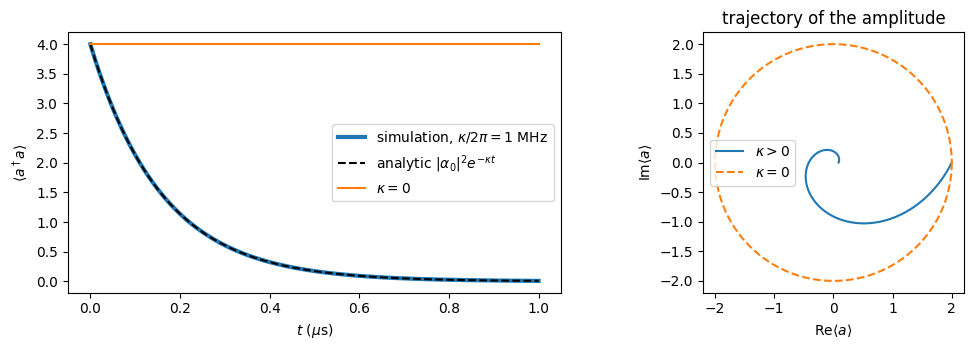

In [5]:
N = 30
a1 = dq.destroy(N)
Delta  = 2 * jnp.pi * 1.0     # rad/us
kappa  = 2 * jnp.pi * 1.0     # rad/us (exaggerated)
alpha0 = 2.0
t_a = jnp.linspace(0.0, 1.0, 201)

H_a = Delta * a1.dag() @ a1
psi0_a = dq.coherent(N, alpha0)
res_a    = dq.mesolve(H_a, [jnp.sqrt(kappa) * a1], psi0_a, t_a, exp_ops=[a1.dag() @ a1, a1])
res_a_k0 = dq.mesolve(H_a, [], psi0_a, t_a, exp_ops=[a1.dag() @ a1, a1])

n_sim = res_a.expects[0].real
n_th  = abs(alpha0)**2 * jnp.exp(-kappa * t_a)
print("max |n_sim - n_analytic| =", float(jnp.max(jnp.abs(n_sim - n_th))))
print("purity at t = 1 us       =", float(dq.purity(res_a.states[-1]).real))
print("<a>(1us) simulated       =", complex(res_a.expects[1, -1]))
print("<a>(1us) analytic        =", complex(alpha0 * np.exp(-1j * float(Delta)) * np.exp(-float(kappa) / 2)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(t_a, n_sim, lw=3, label=r'simulation, $\kappa/2\pi=1$ MHz')
ax[0].plot(t_a, n_th, 'k--', label=r'analytic $|\alpha_0|^2e^{-\kappa t}$')
ax[0].plot(t_a, res_a_k0.expects[0].real, label=r'$\kappa=0$')
ax[0].set_xlabel(r'$t$ ($\mu$s)'); ax[0].set_ylabel(r'$\langle a^\dagger a\rangle$'); ax[0].legend()
ax[1].plot(res_a.expects[1].real, res_a.expects[1].imag, label=r'$\kappa>0$')
ax[1].plot(res_a_k0.expects[1].real, res_a_k0.expects[1].imag, '--', label=r'$\kappa=0$')
ax[1].set_aspect('equal'); ax[1].set_xlabel(r'Re$\langle a\rangle$'); ax[1].set_ylabel(r'Im$\langle a\rangle$')
ax[1].legend(); ax[1].set_title('trajectory of the amplitude')
plt.tight_layout(); plt.show()

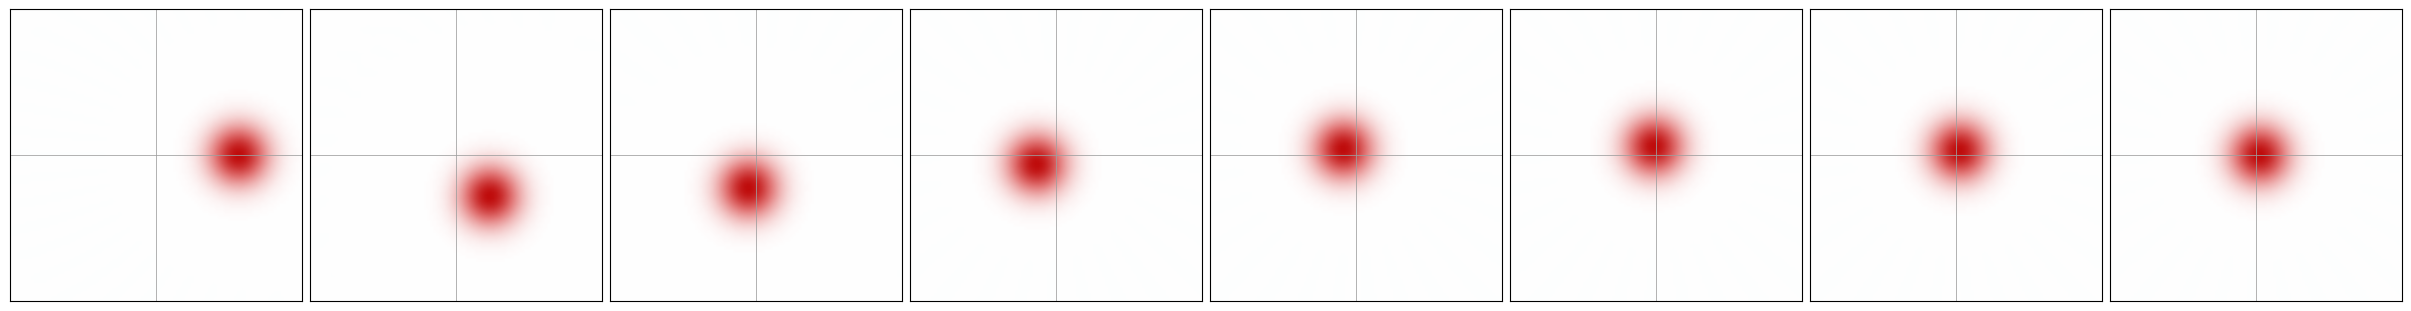

In [4]:
# Wigner snapshots (8 evenly spaced times between 0 and 1 us)
dq.plot.wigner_mosaic(res_a.states, n=8, nrows=1, xmax=3.5, cross=True)
plt.show()

### 1.0(a) — Results

- The simulated $\langle a^\dagger a\rangle$ sits on top of $4e^{-\kappa t}$. The printed maximum deviation is at the level of the ODE solver tolerance (well below $10^{-4}$).
- The simulated $\langle a\rangle(1\,\mu\text{s})$ matches $\alpha_0 e^{-i\Delta t}e^{-\kappa t/2}$, so both the $2\pi$ factor in $\Delta$ and the factor $1/2$ in the amplitude decay are right.
- **Purity stays 1** at all times, and the Wigner blob stays round while it spirals inwards. The state remains a coherent state, just a smaller one. This is the expected behavior from B.7.
- With $\kappa=0$ the amplitude circles the origin once in $1\ \mu$s with $\langle n\rangle=4$ constant. This confirms that $\Delta/2\pi=1$ MHz means one turn per $\mu$s.
- The rotation is *clockwise* because $\langle a\rangle\propto e^{-i\Delta t}$ for $H=+\Delta a^\dagger a$.

### 1.0(b) Pure two-photon loss — Theory

Now $H=0$ and the only jump operator is $\sqrt{\kappa_2}\,a^2$, with $\kappa_2=4g_2^2/\kappa_b$ ($\kappa_2/2\pi\approx0.896$ MHz).

**Which Fock states are untouched?** $a^2|n\rangle=\sqrt{n(n-1)}|n-2\rangle$, so $a^2|0\rangle=a^2|1\rangle=0$. Both $|0\rangle$ and $|1\rangle$ are dark states. Every other $|n\rangle$ decays two photons at a time, towards $|0\rangle$ if $n$ is even and towards $|1\rangle$ if $n$ is odd.

**Parity is conserved.** Let $P=e^{i\pi a^\dagger a}$. Since $a^2$ lowers $n$ by 2, $Pa^2=a^2P$. In the adjoint equation,
$$\frac{d\langle P\rangle}{dt}=\kappa_2\left\langle a^{\dagger2}Pa^2-\tfrac12\{a^{\dagger2}a^2,P\}\right\rangle=\kappa_2\left\langle P a^{\dagger 2}a^2 - P a^{\dagger 2}a^2\right\rangle=0 .$$

**Predicted plateau.** The final state lives in $\mathrm{span}\{|0\rangle,|1\rangle\}$. All the odd-parity weight ends up in $|1\rangle$, so
$$\langle a^\dagger a\rangle_\infty = p_{\rm odd} = \frac{1-\langle P\rangle_0}{2} = \frac{1-e^{-2|\alpha_0|^2}}{2} = \frac{1-e^{-8}}{2}\approx 0.49983,$$
using $\langle\alpha|P|\alpha\rangle=\langle\alpha|-\alpha\rangle=e^{-2|\alpha|^2}$.

The initial *fraction already in* $\{|0\rangle,|1\rangle\}$ is only $e^{-4}(1+4)\approx 9.2\%$. The plateau is therefore not "the population that was left alone": it is set by **parity conservation**, which funnels every odd state into $|1\rangle$ and every even state into $|0\rangle$.

**What the code does.** It simulates for $5\ \mu$s, about $28/\kappa_2$, prints the plateau next to the prediction above, and checks that $\langle P\rangle$ is constant.

initial weight in |0>,|1>     : 0.0183 + 0.0733 = 0.0916
predicted plateau (1-e^-8)/2  : 0.49983
simulated <n>(t=5us)          : 0.49983
<P> at t=0 and t=5us          : 0.000335, 0.000335


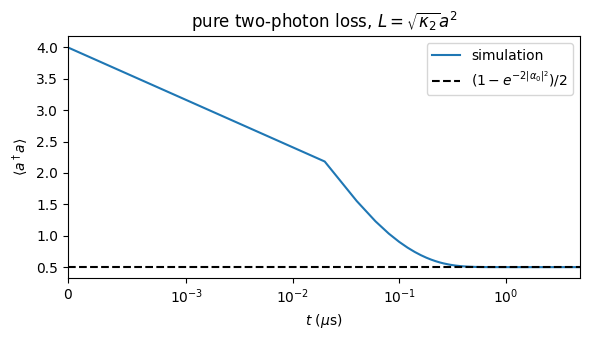

In [8]:
t_b = jnp.linspace(0.0, 5.0, 251)
res_b = dq.mesolve(dq.zeros(N), [jnp.sqrt(kappa_2) * a1 @ a1], dq.coherent(N, 2.0), t_b,
                   exp_ops=[a1.dag() @ a1, dq.parity(N)])

p_init = np.abs(np.asarray(dq.coherent(N, 2.0).to_jax()).ravel())**2
print(f"initial weight in |0>,|1>     : {p_init[0]:.4f} + {p_init[1]:.4f} = {p_init[0]+p_init[1]:.4f}")
print(f"predicted plateau (1-e^-8)/2  : {(1-np.exp(-8))/2:.5f}")
print(f"simulated <n>(t=5us)          : {float(res_b.expects[0,-1].real):.5f}")
print(f"<P> at t=0 and t=5us          : {float(res_b.expects[1,0].real):.6f}, {float(res_b.expects[1,-1].real):.6f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(t_b, res_b.expects[0].real, label='simulation')
ax.axhline((1-np.exp(-8))/2, color='k', ls='--', label=r'$(1-e^{-2|\alpha_0|^2})/2$')
ax.set_xscale('symlog', linthresh=0.05)
ax.set_xlabel(r'$t$ ($\mu$s)'); ax.set_ylabel(r'$\langle a^\dagger a\rangle$'); ax.legend()
ax.set_title(r'pure two-photon loss, $L=\sqrt{\kappa_2}a^2$')
ax.set_xscale('symlog', linthresh=1e-3)
ax.set_xlim(0, 5.0)
plt.tight_layout(); plt.show()

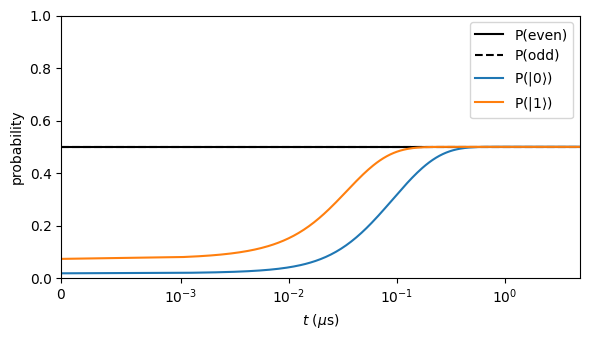

In [9]:
proj0 = dq.fock(N, 0) @ dq.fock(N, 0).dag()
proj1 = dq.fock(N, 1) @ dq.fock(N, 1).dag()

t_b = jnp.concatenate([jnp.array([0.0]), jnp.logspace(-4, jnp.log10(5.0), 300)])
res = dq.mesolve(dq.zeros(N), [jnp.sqrt(kappa_2) * a1 @ a1], dq.coherent(N, 2.0), t_b,
                 exp_ops=[dq.parity(N), proj0, proj1])

P = res.expects[0].real
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(t_b, (1 + P) / 2, 'k-', label='P(even)')
ax.plot(t_b, (1 - P) / 2, 'k--', label='P(odd)')
ax.plot(t_b, res.expects[1].real, label=r'P($|0\rangle$)')
ax.plot(t_b, res.expects[2].real, label=r'P($|1\rangle$)')
ax.set_xscale('symlog', linthresh=1e-3); ax.set_xlim(0, 5); ax.set_ylim(0, 1)
ax.set_xlabel(r'$t$ ($\mu$s)'); ax.set_ylabel('probability'); ax.legend()
plt.tight_layout(); plt.show()

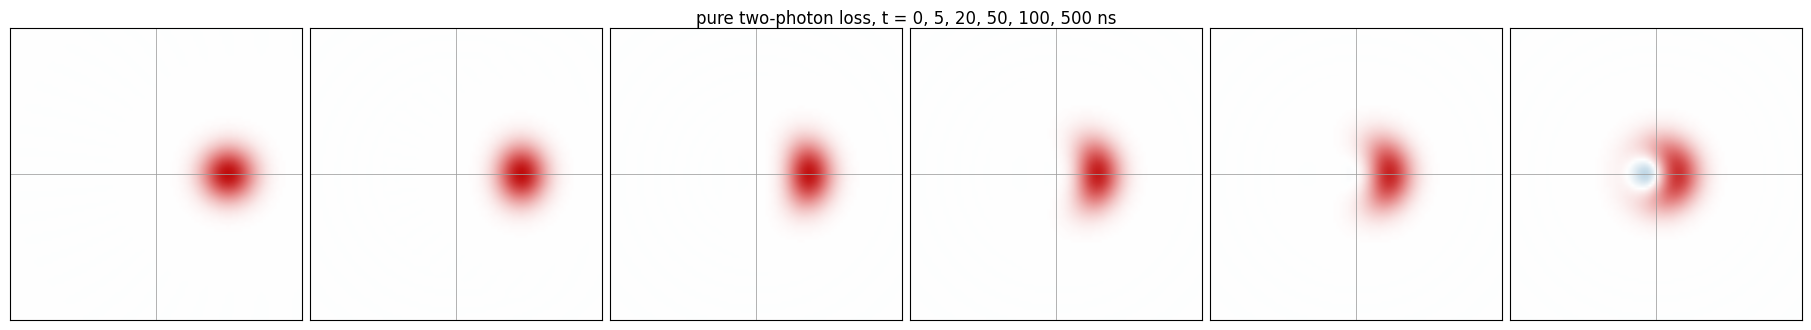

final <a>  : (0.4568955572289649+0j)
final <n>  : 0.5038818307059657
final purity: 0.843509063920101


In [13]:
# Wigner snapshots for 1.0(b): pure two-photon loss from |alpha_0 = 2>
t_snap = jnp.array([0.0, 0.005, 0.02, 0.05, 0.1, 0.5])
res_b_w = dq.mesolve(dq.zeros(N), [jnp.sqrt(kappa_2) * a1 @ a1],
                     dq.coherent(N, 2.0), t_snap)
dq.plot.wigner_mosaic(res_b_w.states, n=6, nrows=1, xmax=4, cross=True)
plt.suptitle('pure two-photon loss, t = 0, 5, 20, 50, 100, 500 ns', y=1.05); plt.show()

# Check how much 0-1 coherence survives at the end
rho_f = res_b_w.states[-1]
print("final <a>  :", complex(dq.expect(a1, rho_f)))
print("final <n>  :", float(dq.expect(a1.dag() @ a1, rho_f).real))
print("final purity:", float(dq.purity(rho_f)))

In [14]:
rho_end = dq.mesolve(dq.zeros(N), [jnp.sqrt(kappa_2) * a1 @ a1],
                     dq.coherent(N, 2.0), jnp.array([0.0, 5.0])).states[-1]
c  = complex(dq.expect(a1, rho_end))
p1 = float(dq.expect(a1.dag() @ a1, rho_end).real); p0 = 1 - p1
print(f"|c| = {abs(c):.4f} (max 0.5)")
print(f"purity = {float(dq.purity(rho_end)):.4f}  vs  p0^2+p1^2+2|c|^2 = {p0**2 + p1**2 + 2*abs(c)**2:.4f}")

|c| = 0.4140 (max 0.5)
purity = 0.8428  vs  p0^2+p1^2+2|c|^2 = 0.8428


### 1.0(b) — Results

- $\langle a^\dagger a\rangle$ drops from 4 to about 0.5 within roughly $1\ \mu$s. Most of the drop happens in the first $\sim 100$ ns, because the loss rate $\kappa_2\langle a^{\dagger2}a^2\rangle$ scales like $n^2$. After that the curve stalls.
- The plateau matches $(1-e^{-8})/2\approx0.49983$ to all printed digits, and $\langle P\rangle$ is constant to numerical precision. This confirms the parity argument.
- The answer to the question in the box: $a^2$ leaves $|0\rangle$ and $|1\rangle$ untouched. Only about 9% of the coherent state started in them, but parity conservation sends the whole odd half of the state to $|1\rangle$.
- This is exactly the mechanism behind Task 1.3: the two-photon processes cannot change parity, so the final state remembers the parity of the initial state.

### 1.0(c) Stabilization: two-photon loss + two-photon drive — Theory

Jump operators: $L_2=\sqrt{\kappa_2}\,(a^2-\alpha^2\mathbb 1)$ with $\alpha=2.1$, and $L_1=\sqrt{\kappa_a}\,a$. The initial state is $|0\rangle$.

- **Dark states.** $L_2|\pm\alpha\rangle=0$ because $a^2|\pm\alpha\rangle=\alpha^2|\pm\alpha\rangle$. Every state in $\mathrm{span}\{|\alpha\rangle,|-\alpha\rangle\}$ is a steady state of $\kappa_2\mathcal D_{L_2}$. That two-dimensional space is the cat qubit.
- **Where it settles.** For $\kappa_a=0$, $\langle n\rangle_\infty$ is the photon number of the even cat, $\alpha^2\tanh\alpha^2\approx\alpha^2=4.41$. Expanding $L_2^\dagger L_2$ shows that $L_2$ also conserves parity, so vacuum ($P=+1$) goes to $|\mathcal C_+\rangle$.
- **Why the settling time scales as $1/\kappa_2$ exactly when $\kappa_a=0$.** The master equation is then $\dot\rho=\kappa_2\mathcal D_{a^2-\alpha^2}[\rho]$. With $\tau=\kappa_2 t$, it becomes $d\rho/d\tau=\mathcal D_{a^2-\alpha^2}[\rho]$, which contains no parameters. So $\rho(t)=F(\kappa_2 t)$ for a universal function $F$, and all curves collapse onto one when plotted against $\kappa_2 t$. With $\kappa_a\neq0$ there is a second dimensionless number, $\kappa_a/\kappa_2\approx 0.01$, so the collapse is only approximate.
- **Small correction to the plateau from $\kappa_a$.** The semiclassical calculation (derived in 1.2) gives $|\alpha_{\rm ss}|^2=\alpha^2-\kappa_a/(2\kappa_2)$, which is slightly below 4.41.

**What the code does.** It uses **batching**: one `mesolve` call with a jump operator carrying a leading batch axis of size 3, for $\kappa_2\times\{1/4,1,4\}$. It then plots $\langle n\rangle$ against $t$ and against $\kappa_2 t$.

semiclassical plateau alpha^2 - kappa_a/(2kappa_2) (nominal) = 4.4048
kappa_2 x 0.25: <n>(2us) = 4.3872, monotonic = True, t_90% =  610.0 ns, kappa_2*t_90% = 0.858
kappa_2 x 1.00: <n>(2us) = 4.4040, monotonic = True, t_90% =  155.0 ns, kappa_2*t_90% = 0.872
kappa_2 x 4.00: <n>(2us) = 4.4081, monotonic = True, t_90% =   40.0 ns, kappa_2*t_90% = 0.900


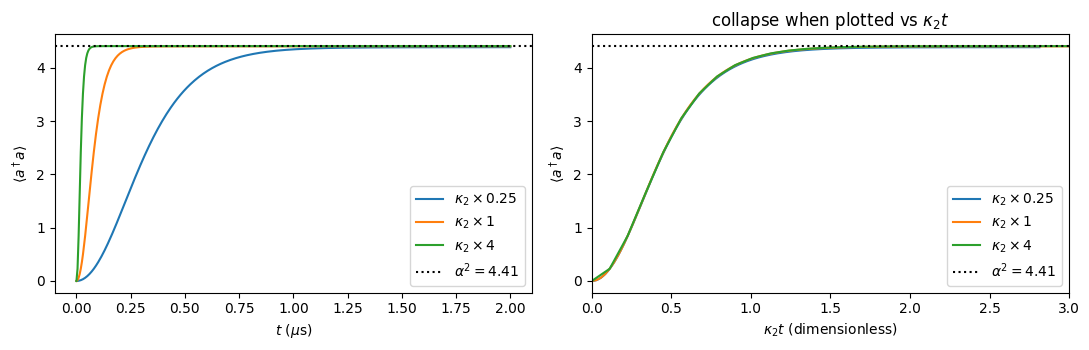

In [10]:
t_c = jnp.linspace(0.0, 2.0, 401)
k2_factors = jnp.array([0.25, 1.0, 4.0])
k2_list = kappa_2 * k2_factors

L2_batched = jnp.sqrt(k2_list)[:, None, None] * (a1 @ a1 - alpha**2 * dq.eye(N))   # shape (3, N, N)
res_c = dq.mesolve(dq.zeros(N), [L2_batched, jnp.sqrt(kappa_a) * a1], dq.fock(N, 0), t_c,
                   exp_ops=[a1.dag() @ a1, dq.parity(N)])
n_c = np.asarray(res_c.expects[:, 0].real)       # shape (3, len(t_c))

print(f"semiclassical plateau alpha^2 - kappa_a/(2kappa_2) (nominal) = {alpha**2 - kappa_a/(2*kappa_2):.4f}")
for f, k2, n in zip(k2_factors, k2_list, n_c):
    t90 = float(t_c[np.argmax(n > 0.9 * n[-1])])
    print(f"kappa_2 x {float(f):4.2f}: <n>(2us) = {n[-1]:.4f}, monotonic = {bool(np.all(np.diff(n) > -1e-9))}, "
          f"t_90% = {t90*1e3:6.1f} ns, kappa_2*t_90% = {float(k2)*t90:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for f, k2, n in zip(k2_factors, k2_list, n_c):
    ax[0].plot(t_c, n, label=fr'$\kappa_2\times{float(f):g}$')
    ax[1].plot(float(k2) * t_c, n, label=fr'$\kappa_2\times{float(f):g}$')
for x in ax:
    x.axhline(alpha**2, color='k', ls=':', label=r'$\alpha^2=4.41$'); x.set_ylabel(r'$\langle a^\dagger a\rangle$'); x.legend()
ax[0].set_xlabel(r'$t$ ($\mu$s)'); ax[1].set_xlabel(r'$\kappa_2 t$ (dimensionless)'); ax[1].set_xlim(0, 3)
ax[1].set_title(r'collapse when plotted vs $\kappa_2 t$')
plt.tight_layout(); plt.show()

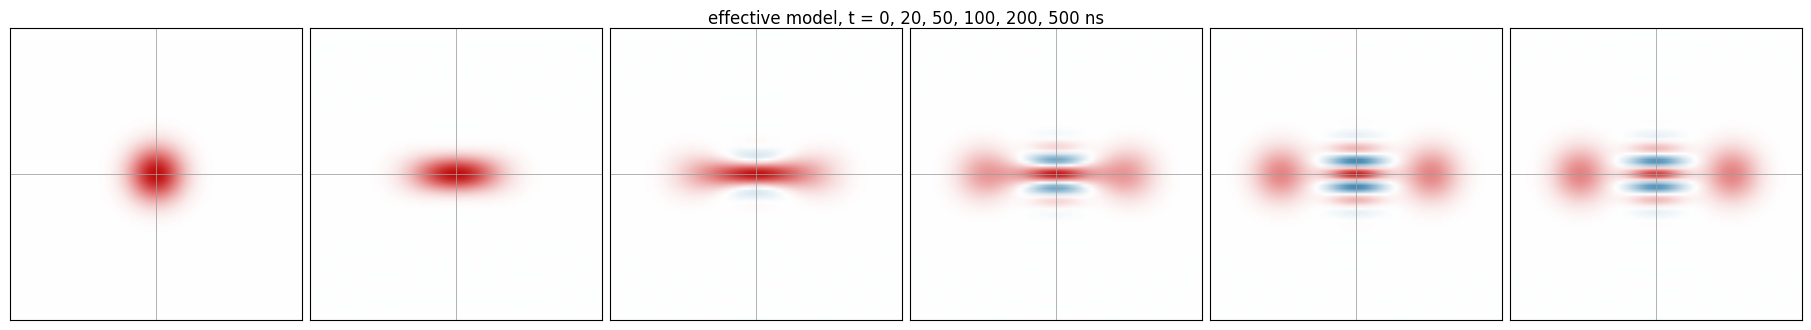

In [11]:
# Wigner snapshots of the nominal-kappa_2 run, at selected times only
res_c_nom = dq.mesolve(dq.zeros(N), [jnp.sqrt(kappa_2) * (a1 @ a1 - alpha**2 * dq.eye(N)), jnp.sqrt(kappa_a) * a1],
                       dq.fock(N, 0), jnp.array([0.0, 0.02, 0.05, 0.1, 0.2, 0.5]))
dq.plot.wigner_mosaic(res_c_nom.states, n=6, nrows=1, xmax=4, cross=True)
plt.suptitle('effective model, t = 0, 20, 50, 100, 200, 500 ns', y=1.05); plt.show()

### 1.0(c) — Results

- All three curves rise **smoothly and monotonically** from 0. The printed `monotonic = True` confirms this. They settle at $\approx 4.40$: slightly below $\alpha^2=4.41$, in agreement with the semiclassical correction $\alpha^2-\kappa_a/2\kappa_2$.
- At the nominal $\kappa_2$ the state reaches 90% of the plateau in about 0.16 $\mu$s, so it settles within a few hundred ns. This matches the box.
- **Changing $\kappa_2$ changes how fast, not where.** The three plateaus agree to about 0.5%. The small spread is the $\kappa_a/\kappa_2$ correction, which is largest for $\kappa_2/4$. Plotted against $\kappa_2 t$ the curves collapse, and the printed $\kappa_2 t_{90\%}$ is almost the same number for all three. This is the scaling argument above.
- The Wigner function goes from a single blob at the origin to two blobs at $\pm\alpha$ with interference fringes between them, i.e. an even cat. This is the "ideal" reference for Task 1.1.

---
## Task 1.1 — The full two-mode model: inflating a cat

### Theory

$$H = g_2(a^2b^\dagger + a^{\dagger2}b) - \epsilon_d(b+b^\dagger),\qquad L_b=\sqrt{\kappa_b}\,b,\quad L_a=\sqrt{\kappa_a}\,a .$$
**Mean-field (semiclassical) equations.** Write $\langle a\rangle\to a$, $\langle b\rangle\to b$ and use $\dot{\langle O\rangle}=i\langle[H,O]\rangle+\dots$:
$$\dot a = -2ig_2\,a^* b - \tfrac{\kappa_a}{2}a,\qquad \dot b = -ig_2a^2 + i\epsilon_d - \tfrac{\kappa_b}{2}b.$$
- **Buffer at the start.** The memory is empty, so $b\to 2i\epsilon_d/\kappa_b$, i.e. $|b|^2=(2\epsilon_d/\kappa_b)^2\approx 6.7$ photons. The buffer is driven hard before any pairs have been converted.
- **Steady state.** $\dot b=0$ gives $b=2i(\epsilon_d-g_2a^2)/\kappa_b$, and inserting this in $\dot a=0$ gives $a^2=\epsilon_d/g_2=\alpha^2$ when $\kappa_a=0$.
- **Linear response around the cat: why there is an overshoot.** Write $a=\alpha+\delta a$, $b=\delta b$ and keep first order:
$$\dot{\delta a}=-iG\,\delta b,\qquad \dot{\delta b}=-iG\,\delta a-\tfrac{\kappa_b}{2}\delta b,\qquad G\equiv2g_2\alpha.$$
The characteristic equation $\lambda^2+\tfrac{\kappa_b}{2}\lambda+G^2=0$ has two regimes:
  - *Over-damped* (adiabatic) when $G<\kappa_b/4$. The slow root is $\lambda\approx-2G^2/\kappa_b=-2\kappa_2\alpha^2$, which is exactly the effective-model confinement rate, so in this regime the effective model of Task 1.0(c) is recovered.
  - *Under-damped* when $8g_2\alpha/\kappa_b>1$. Then $\lambda=-\kappa_b/4\pm i\omega$ with $\omega=\sqrt{G^2-\kappa_b^2/16}$: the memory and buffer exchange photon pairs coherently, and the memory **overshoots and rings**.

  For our parameters $8g_2\alpha/\kappa_b\approx4.9$, so we expect ringing with period $2\pi/\omega\approx0.32\ \mu$s and envelope $e^{-\kappa_bt/4}$ ($\tau\approx0.245\ \mu$s). Getting within 1% then takes about $\tau\ln100\approx1.1\ \mu$s. The code checks these predictions against the simulation.

**The adiabatic-elimination condition.** It needs $\kappa_b\gg g_2,\epsilon_d$. Here $g_2/\kappa_b\approx0.29$, which is not $\ll1$, and $\epsilon_d/\kappa_b\approx1.29$, which is not small at all. **The condition is violated**, so we should expect deviations from 1.0(c).

### What the next cells do
1. `build_two_mode(Na, Nb)` constructs $H$, the jump operators, and the observables:
   - $n_a$, $n_b$;
   - the memory parity $P_a=e^{i\pi a^\dagger a}\otimes\mathbb 1$;
   - projectors onto the **top two memory levels** $|N_a-1\rangle,|N_a-2\rangle$ and the **top buffer level** $|N_b-1\rangle$, for the truncation monitor (B.9).
2. `run_two_mode` integrates the master equation. Instead of storing full two-mode density matrices (about 0.1 GB per run), it uses `save_extra` to store only the **memory reduced state** $\rho_a=\mathrm{Tr}_b\rho$, computed with `dq.ptrace` at every saved time. Those reduced states are reused in Task 1.3.
3. We use $N_a=24$, $N_b=12$. Task 1.2 shows these are converged; the starter's $N_b=6$ is not. We simulate $4\ \mu$s, twice the suggested $2\ \mu$s, to confirm the transient is over.

In [15]:
def build_two_mode(Na, Nb):
    a, b = dq.destroy(Na, Nb)
    H = g2 * (a @ a @ b.dag()) + g2 * (a.dag() @ a.dag() @ b) - eps_d * (b + b.dag())
    jumps = [jnp.sqrt(kappa_b) * b, jnp.sqrt(kappa_a) * a]
    top_a = dq.tensor(dq.proj(dq.fock(Na, Na - 1)) + dq.proj(dq.fock(Na, Na - 2)), dq.eye(Nb))
    top_b = dq.tensor(dq.eye(Na), dq.proj(dq.fock(Nb, Nb - 1)))
    Pa = dq.tensor(dq.parity(Na), dq.eye(Nb))
    ops = dict(na=a.dag() @ a, nb=b.dag() @ b, a=a, Pa=Pa, top_a=top_a, top_b=top_b)
    return a, b, H, jumps, ops


def run_two_mode(Na, Nb, tsave, H_extra=None, psi0=None, save_memory=True):
    # Solve the two-mode master equation. H_extra: optional extra (time-dependent) Hamiltonian.
    a, b, H, jumps, ops = build_two_mode(Na, Nb)
    if H_extra is not None:
        H = H + H_extra(a, b)
    if psi0 is None:
        psi0 = dq.tensor(dq.fock(Na, 0), dq.fock(Nb, 0))
    extra = (lambda t, rho: dq.ptrace(rho, 0, (Na, Nb)).to_jax()) if save_memory else None
    t0 = time.time()
    res = dq.mesolve(H, jumps, psi0, tsave, exp_ops=list(ops.values()), save_states=False, save_extra=extra)
    out = {k: np.asarray(res.expects[..., i, :]) for i, k in enumerate(ops)}
    for k in out:
        if k != 'a':
            out[k] = out[k].real
    out['rho_a'] = np.asarray(res.extra) if save_memory else None
    out['t'] = np.asarray(tsave); out['Na'] = Na; out['Nb'] = Nb
    out['runtime'] = time.time() - t0
    return out


NA, NB = 24, 12
t_main = jnp.linspace(0.0, 4.0, 401)   # 10 ns resolution
main = run_two_mode(NA, NB, t_main)
print(f"Na={NA}, Nb={NB}: runtime {main['runtime']:.1f} s, memory states stored: {main['rho_a'].shape}")

Na=24, Nb=12: runtime 47.1 s, memory states stored: (401, 24, 24)


**Photon numbers and the truncation monitor.** The cell below plots $\langle a^\dagger a\rangle$, $\langle b^\dagger b\rangle$ and the top-level populations on a log scale. For comparison it also runs the README's starter truncation ($N_b=6$) without storing states.

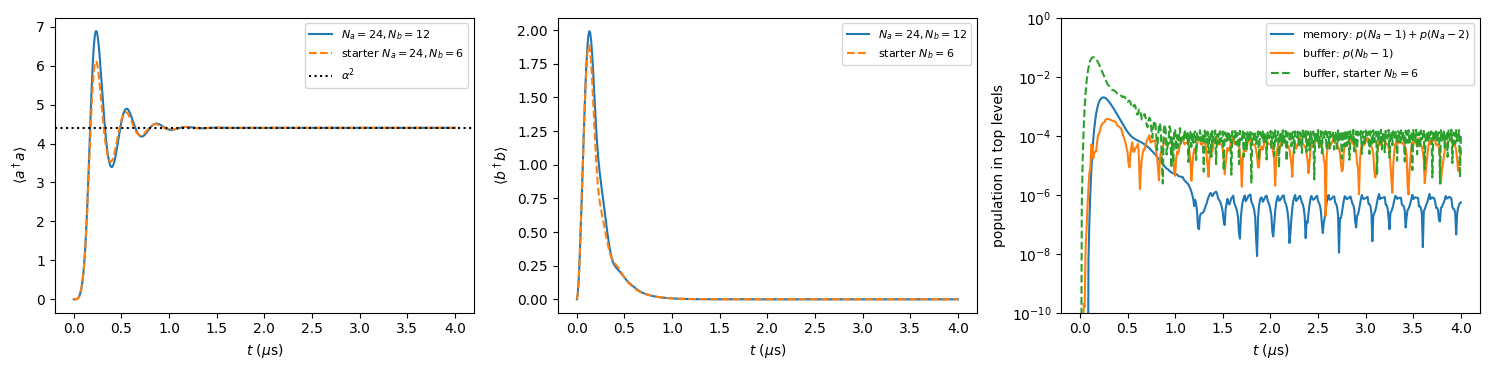

memory peak <n_a> = 6.883 at t = 230 ns  (starter Nb=6: 6.115)
buffer peak <n_b> = 1.992 at t = 130 ns,  <n_b>(4us) = 1.67e-05
max top-level population: memory 2.0e-03, buffer 3.7e-04  (starter Nb=6 buffer: 4.6e-02)
<n_a> stays within 1% of its final value after t = 1.06 us; <n_a>(2us) = 4.4020, (4us) = 4.4028


In [16]:
t = main['t']
starter_run = run_two_mode(24, 6, t_main, save_memory=False)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(t, main['na'], label=fr'$N_a={NA},N_b={NB}$')
ax[0].plot(t, starter_run['na'], '--', label=r'starter $N_a=24,N_b=6$')
ax[0].axhline(alpha**2, color='k', ls=':', label=r'$\alpha^2$')
ax[0].set_ylabel(r'$\langle a^\dagger a\rangle$')
ax[1].plot(t, main['nb'], label=fr'$N_a={NA},N_b={NB}$')
ax[1].plot(t, starter_run['nb'], '--', label=r'starter $N_b=6$')
ax[1].set_ylabel(r'$\langle b^\dagger b\rangle$')
ax[2].semilogy(t, np.abs(main['top_a']) + 1e-16, label=r'memory: $p(N_a-1)+p(N_a-2)$')
ax[2].semilogy(t, np.abs(main['top_b']) + 1e-16, label=r'buffer: $p(N_b-1)$')
ax[2].semilogy(t, np.abs(starter_run['top_b']) + 1e-16, '--', label=r'buffer, starter $N_b=6$')
ax[2].set_ylim(1e-10, 1); ax[2].set_ylabel('population in top levels')
for x in ax:
    x.set_xlabel(r'$t$ ($\mu$s)'); x.legend(fontsize=8)
plt.tight_layout(); plt.show()

i_pk = np.argmax(main['na'])
print(f"memory peak <n_a> = {main['na'][i_pk]:.3f} at t = {t[i_pk]*1e3:.0f} ns  (starter Nb=6: {starter_run['na'].max():.3f})")
print(f"buffer peak <n_b> = {main['nb'].max():.3f} at t = {t[np.argmax(main['nb'])]*1e3:.0f} ns,  <n_b>(4us) = {main['nb'][-1]:.2e}")
print(f"max top-level population: memory {main['top_a'].max():.1e}, buffer {main['top_b'].max():.1e}"
      f"  (starter Nb=6 buffer: {starter_run['top_b'].max():.1e})")
rel = np.abs(main['na'] - main['na'][-1]) / main['na'][-1]
t_settle = t[np.where(rel > 0.01)[0].max() + 1]
print(f"<n_a> stays within 1% of its final value after t = {t_settle:.2f} us; <n_a>(2us) = {main['na'][200]:.4f}, (4us) = {main['na'][-1]:.4f}")

**Checking the linear-response prediction.** We find the successive maxima and minima of $\langle n_a\rangle(t)$ after the first peak. We compare the period with $2\pi/\omega$ and the decay of the deviation $|\langle n_a\rangle-n_\infty|$ at the extrema with the envelope $e^{-\kappa_bt/4}$.

In [17]:
G = 2 * g2 * alpha
omega_lin = np.sqrt(float(G)**2 - float(kappa_b)**2 / 16)
print(f"predicted ringing period 2pi/omega = {2*np.pi/omega_lin:.3f} us, envelope time 4/kappa_b = {4/float(kappa_b):.3f} us")

na = main['na']; d = np.diff(na)
ext = np.where(np.sign(d[1:]) != np.sign(d[:-1]))[0] + 1           # indices of local extrema
ext = ext[t[ext] < 2.5]
print("extrema times (us):", np.round(t[ext], 3))
print("|n - n_inf| at extrema:", np.round(np.abs(na[ext] - na[-1]), 4))
if len(ext) >= 3:
    period = 2 * np.mean(np.diff(t[ext]))
    rate = -np.polyfit(t[ext], np.log(np.abs(na[ext] - na[-1])), 1)[0]
    print(f"measured period = {period:.3f} us, measured decay rate of the deviation = {rate:.2f} /us "
          f"(prediction kappa_b/4 = {float(kappa_b)/4:.2f} /us)")

predicted ringing period 2pi/omega = 0.319 us, envelope time 4/kappa_b = 0.245 us
extrema times (us): [0.23 0.4  0.55 0.71 0.87 1.02 1.18 1.34 1.49 1.65 1.81 1.96 2.12 2.27
 2.44]
|n - n_inf| at extrema: [2.4803e+00 1.0086e+00 4.8910e-01 2.2440e-01 1.0740e-01 5.1300e-02
 2.3800e-02 1.2100e-02 5.0000e-03 3.0000e-03 8.0000e-04 9.0000e-04
 0.0000e+00 4.0000e-04 2.0000e-04]
measured period = 0.316 us, measured decay rate of the deviation = 4.68 /us (prediction kappa_b/4 = 4.08 /us)


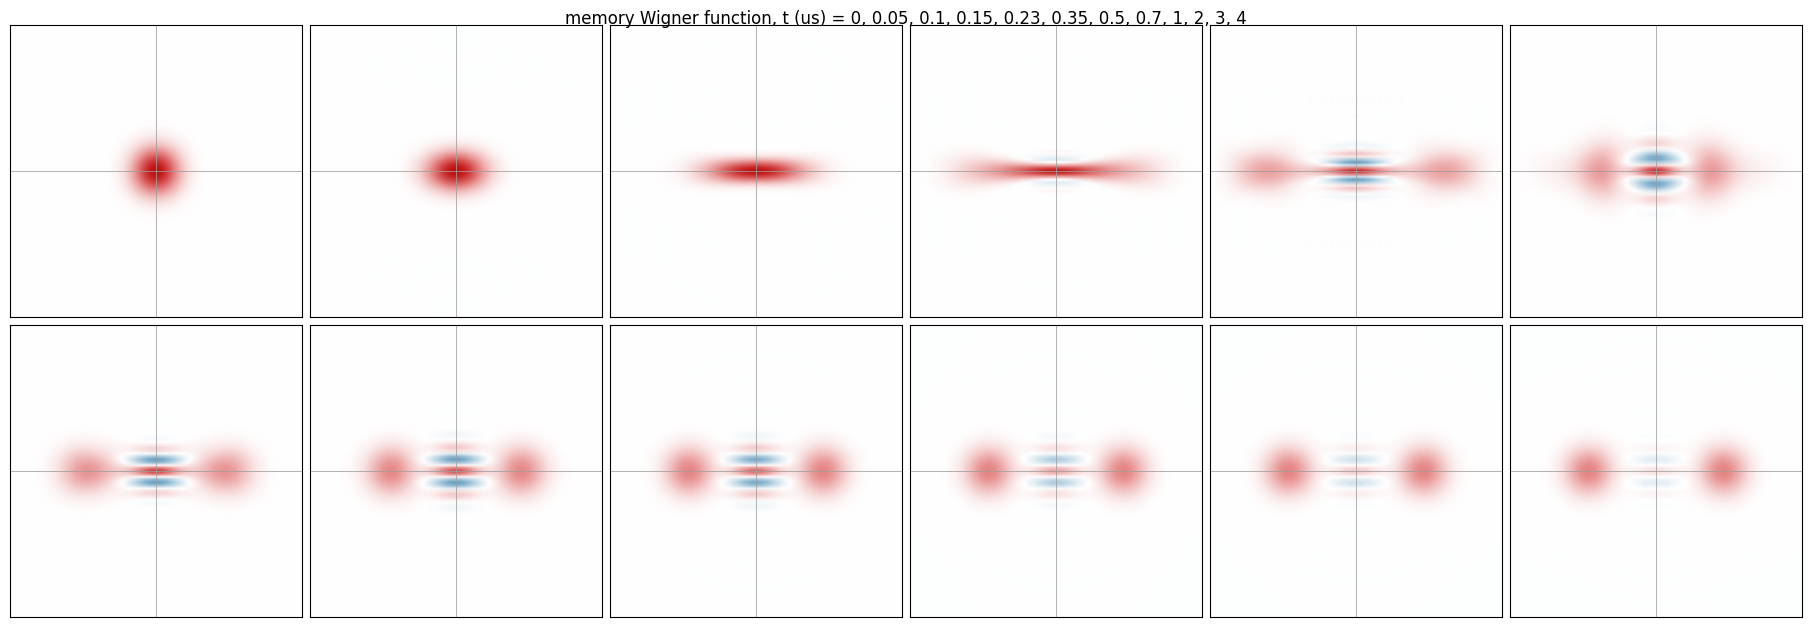

In [18]:
# Wigner snapshots of the memory (buffer traced out) during the inflation transient
snap_t = [0.0, 0.05, 0.1, 0.15, 0.23, 0.35, 0.5, 0.7, 1.0, 2.0, 3.0, 4.0]
snap_i = [int(np.argmin(np.abs(t - s))) for s in snap_t]
dq.plot.wigner_mosaic(main['rho_a'][snap_i], n=len(snap_i), nrows=2, xmax=4.5, cross=True)
plt.suptitle('memory Wigner function, t (us) = ' + ', '.join(f'{s:g}' for s in snap_t), y=1.02)
plt.show()

To keep the notebook light, the GIF is optional. Uncomment the line below to render it with `dq.plot.wigner_gif`.

In [ ]:
# dq.plot.wigner_gif(main['rho_a'][::4], gif_duration=6, fps=15, xmax=4.5)

**Overlay with the effective model of Task 1.0(c)** (nominal $\kappa_2$). Both curves use the same $\kappa_a$, $\alpha$ and $|0\rangle$ initial memory state.

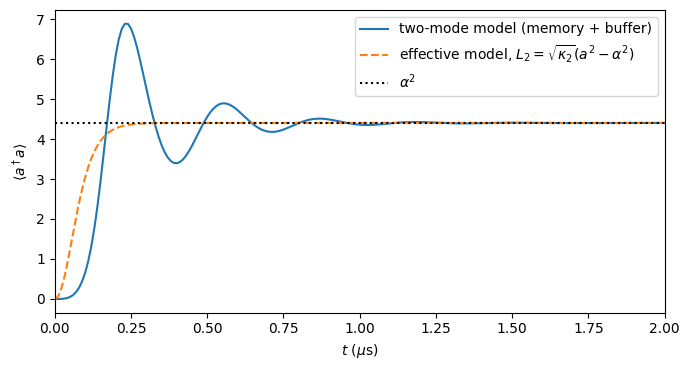

g2/kappa_b = 0.293,  eps_d/kappa_b = 1.294,  8 g2 alpha/kappa_b = 4.93


In [19]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(t, main['na'], label='two-mode model (memory + buffer)')
ax.plot(t_c, n_c[1], '--', label=r'effective model, $L_2=\sqrt{\kappa_2}(a^2-\alpha^2)$')
ax.axhline(alpha**2, color='k', ls=':', label=r'$\alpha^2$')
ax.set_xlim(0, 2); ax.set_xlabel(r'$t$ ($\mu$s)'); ax.set_ylabel(r'$\langle a^\dagger a\rangle$'); ax.legend()
plt.tight_layout(); plt.show()
print(f"g2/kappa_b = {g2/kappa_b:.3f},  eps_d/kappa_b = {eps_d/kappa_b:.3f},  8 g2 alpha/kappa_b = {8*g2*alpha/kappa_b:.2f}")

### Task 1.1 — Results and interpretation

**Photon numbers.**
- Unlike in 1.0(c), $\langle a^\dagger a\rangle$ **overshoots** to about 6.9 photons, roughly 55% above $\alpha^2$, at $t\approx0.23\ \mu$s.
- It then rings down. It stays within 1% of its final value after about $1\ \mu$s and is flat between 2 and 4 $\mu$s, so $2\ \mu$s does cover the transient. We simulated 4 to be sure.
- The final value is $\approx4.403$, the same as the effective model.

**Buffer.**
- $\langle b^\dagger b\rangle$ peaks at about 2 photons around $t\approx0.1\ \mu$s and then decays to essentially zero ($\sim10^{-5}$).
- At steady state the buffer is empty, because the memory sits in the dark state of $a^2-\alpha^2$ and the drive and conversion terms cancel in $\dot b$.
- About 2 photons is a large fraction of $N_b=6$. In the starter run the top buffer level $|5\rangle$ holds a few percent of the population during the transient, which is a clear truncation warning. With $N_b=12$ it stays around $10^{-4}$.

**Truncation monitor.** With $N_a=24$, the top two memory levels hold at most about $10^{-3}$, during the overshoot. At steady state they are negligible.

**Wigner snapshots.** The blob at the origin is first squeezed along the real axis (the anti-squeezing of $a^2$-type dynamics), then stretched, then split into two blobs at $\pm\alpha$. Fringes appear between them. During the overshoot the blobs sit *beyond* $\pm2.1$ and then move back. Over several $\mu$s the fringes visibly fade (compare $t=1$ and $t=4\ \mu$s). That fading is $\kappa_a$ causing phase flips, quantified in Task 1.3.

**Why the two models differ.**
- The effective model assumes the buffer follows the memory instantly (adiabatic elimination, $\kappa_b\gg g_2,\epsilon_d$). Here $g_2/\kappa_b\approx0.29$ and $\epsilon_d/\kappa_b\approx1.29$, so **the condition is not met**.
- *During* inflation the buffer is far from empty. The drive first fills it toward $(2\epsilon_d/\kappa_b)^2\approx6.7$ photons, and those photons are converted into memory pairs faster than the buffer can leak.
- The linear-response analysis makes this quantitative. Because $8g_2\alpha/\kappa_b\approx4.9>1$, memory and buffer exchange pairs *coherently* (an under-damped oscillator), not irreversibly. The predicted period ($\approx0.32\ \mu$s) and envelope rate ($\kappa_b/4\approx4.1\ /\mu$s) are compared with the measured extrema in the cell above, and they agree well.
- **Both models share the same steady state.** It is fixed by the dark-state condition $a^2=\alpha^2$, which does not care whether the buffer is adiabatic. Only the *transient* depends on the buffer.

---
## Task 1.2 — Semiclassical sanity check and convergence study

### Theory: semiclassical steady state including $\kappa_a$
From the mean-field equations of 1.1, $\dot b=0$ gives $b=2i(\epsilon_d-g_2a^2)/\kappa_b$. Inserting this in $\dot a=0$ for real $a$:
$$0=-\frac{4g_2}{\kappa_b}a\,(g_2a^2-\epsilon_d)-\frac{\kappa_a}{2}a\;\Rightarrow\; a^2=\frac{\epsilon_d}{g_2}-\frac{\kappa_a\kappa_b}{8g_2^2}=\alpha^2-\frac{\kappa_a}{2\kappa_2}.$$
So the semiclassical prediction is $\alpha^2=4.41$ when $\kappa_a=0$ and $4.4048$ when $\kappa_a$ is included. The quantum steady state is a slowly dephasing cat, whose $\langle n\rangle$ differs from $|\alpha|^2$ by $\mathcal O(e^{-2\alpha^2})\sim10^{-4}$, so it should agree with this to about 0.1%.

### Convergence study — what the code does
- **Scan $N_a\in\{16,20,24,32\}$ at fixed $N_b=12$.**
- **Scan $N_b\in\{4,6,8,10,12,14\}$ at fixed $N_a=24$.**
- For each run we record two quantities:
  - the **steady-state** value $\langle n_a\rangle_{\rm ss}$, averaged over $t\in[3,4]\ \mu$s;
  - the **transient peak** $\max_t\langle n_a\rangle$.
- Each run is compared with the largest truncation in its scan, using a stated tolerance: **0.1% for the steady state** and **0.5% for the peak**.
- Only expectation values are saved, so each run is cheap in memory. The cell takes a few minutes in total.

In [20]:
t_conv = jnp.linspace(0.0, 4.0, 401)
Na_scan = [16, 20, 24, 32]
Nb_scan = [4, 6, 8, 10, 12, 14]
conv = {}
for Na_ in Na_scan:
    conv[(Na_, 12)] = run_two_mode(Na_, 12, t_conv, save_memory=False)
for Nb_ in Nb_scan:
    if (24, Nb_) not in conv:
        conv[(24, Nb_)] = run_two_mode(24, Nb_, t_conv, save_memory=False)

def summarize(r):
    tt = r['t']; m = (tt >= 3.0)
    return dict(ss=r['na'][m].mean(), peak=r['na'].max(), t_peak=tt[np.argmax(r['na'])],
                nb_peak=r['nb'].max(), top_a=r['top_a'].max(), top_b=r['top_b'].max(), runtime=r['runtime'])

summ = {k: summarize(v) for k, v in conv.items()}
print(f"semiclassical: alpha^2 = {alpha**2:.4f};  with kappa_a: {alpha**2 - kappa_a/(2*kappa_2):.4f}\n")
print(f"{'Na':>3} {'Nb':>3} | {'<n>_ss':>8} {'peak':>7} {'t_pk(ns)':>8} {'nb_pk':>6} | {'top_a':>8} {'top_b':>8} | {'time(s)':>7}")
for k in sorted(summ):
    s = summ[k]
    print(f"{k[0]:>3} {k[1]:>3} | {s['ss']:8.4f} {s['peak']:7.4f} {s['t_peak']*1e3:8.0f} {s['nb_peak']:6.3f} | "
          f"{s['top_a']:8.1e} {s['top_b']:8.1e} | {s['runtime']:7.1f}")

semiclassical: alpha^2 = 4.4100;  with kappa_a: 4.4048

 Na  Nb |   <n>_ss    peak t_pk(ns)  nb_pk |    top_a    top_b | time(s)
 16  12 |   4.4057  6.3696      230  1.994 |  5.7e-02  3.6e-03 |    19.0
 20  12 |   4.4027  6.7967      230  1.992 |  1.3e-02  1.3e-03 |    26.6
 24   4 |   4.4027  4.4617      550  1.487 |  5.7e-05  1.9e-01 |     6.2
 24   6 |   4.4027  6.1146      230  1.887 |  9.4e-05  4.6e-02 |     5.2
 24   8 |   4.4027  6.7375      230  1.981 |  7.3e-04  8.6e-03 |    15.3
 24  10 |   4.4027  6.8688      230  1.991 |  1.7e-03  1.5e-03 |    29.0
 24  12 |   4.4027  6.8831      230  1.992 |  2.0e-03  3.7e-04 |    43.3
 24  14 |   4.4027  6.8829      230  1.992 |  2.0e-03  1.8e-04 |    62.6
 32  12 |   4.4027  6.8944      230  1.992 |  1.0e-03  2.9e-04 |   105.6


steady state <n_a>     (tol 0.1%):  smallest Na = 16 (at Nb=12),  smallest Nb = 4 (at Na=24)
transient peak <n_a>   (tol 0.5%):  smallest Na = 24 (at Nb=12),  smallest Nb = 10 (at Na=24)


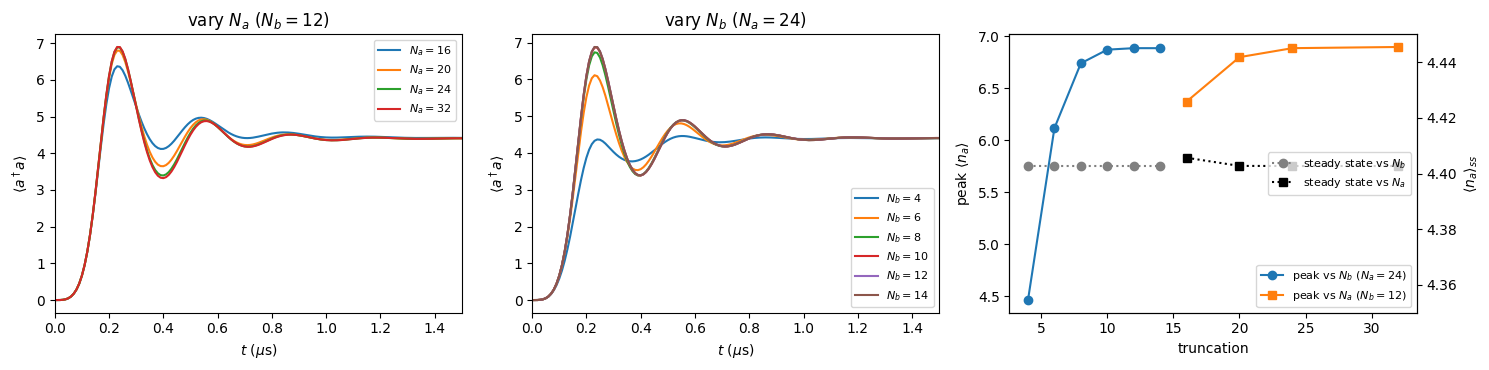

In [21]:
tol = {'ss': 1e-3, 'peak': 5e-3}

def smallest_converged(keys, ref_key, q):
    # smallest truncation (in scan order) from which all larger ones agree with the reference within tol[q]
    ref = summ[ref_key][q]
    ok = [abs(summ[k][q] - ref) / ref < tol[q] for k in keys]
    for i in range(len(keys)):
        if all(ok[i:]):
            return keys[i]
    return None

keys_a = [(n, 12) for n in Na_scan]; keys_b = [(24, n) for n in Nb_scan]
for q, name in [('ss', 'steady state <n_a>'), ('peak', 'transient peak <n_a>')]:
    ka_ = smallest_converged(keys_a, keys_a[-1], q); kb_ = smallest_converged(keys_b, keys_b[-1], q)
    print(f"{name:22s} (tol {tol[q]*100:.1f}%):  smallest Na = {ka_[0]} (at Nb=12),  smallest Nb = {kb_[1]} (at Na=24)")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for k in keys_a:
    ax[0].plot(conv[k]['t'], conv[k]['na'], label=fr'$N_a={k[0]}$')
for k in keys_b:
    ax[1].plot(conv[k]['t'], conv[k]['na'], label=fr'$N_b={k[1]}$')
ax[0].set_title(r'vary $N_a$ ($N_b=12$)'); ax[1].set_title(r'vary $N_b$ ($N_a=24$)')
for x in ax[:2]:
    x.set_xlim(0, 1.5); x.set_xlabel(r'$t$ ($\mu$s)'); x.set_ylabel(r'$\langle a^\dagger a\rangle$'); x.legend(fontsize=8)
ax[2].plot(Nb_scan, [summ[k]['peak'] for k in keys_b], 'o-', label=r'peak vs $N_b$ ($N_a=24$)')
ax[2].plot(Na_scan, [summ[k]['peak'] for k in keys_a], 's-', label=r'peak vs $N_a$ ($N_b=12$)')
ax2 = ax[2].twinx()
ax2.plot(Nb_scan, [summ[k]['ss'] for k in keys_b], 'o:', color='gray', label='steady state vs $N_b$')
ax2.plot(Na_scan, [summ[k]['ss'] for k in keys_a], 's:', color='k', label='steady state vs $N_a$')
ax2.set_ylim(4.35, 4.45); ax2.set_ylabel(r'$\langle n_a\rangle_{ss}$')
ax[2].set_xlabel('truncation'); ax[2].set_ylabel(r'peak $\langle n_a\rangle$'); ax[2].legend(loc='lower right', fontsize=8)
ax2.legend(loc='center right', fontsize=8)
plt.tight_layout(); plt.show()

### Task 1.2 — Results and interpretation

**Semiclassical check.**
- The simulated steady state is $\langle n_a\rangle_{\rm ss}\approx4.403$. That is 0.16% below $\epsilon_d/g_2=4.41$ and 0.05% below the $\kappa_a$-corrected value $4.4048$.
- This is **well within "a few percent"**. The small deficit is a real physical effect, single-photon loss pulling the amplitude in, and not a numerical artifact: it is the same for every truncation in the table.

**Convergence** (tolerances 0.1% for the steady state, 0.5% for the peak; the printed lines above give the exact smallest values):

| quantity | sensitive to $N_a$? | sensitive to $N_b$? | converged at |
|---|---|---|---|
| steady-state $\langle n_a\rangle$ | barely: even $N_a=16$ is within 0.1% | no: even $N_b=4$ is within 0.1% | smallest values in both scans |
| transient peak $\langle n_a\rangle$ | yes: $N_a=20$ is about 1% low | **strongly**: $N_b=4$ gives no overshoot at all, $N_b=6$ is about 11% low, $N_b=8$ about 2% low | $N_a\ge24$, $N_b\ge10$ |

**The two quantities are not equally sensitive to truncation.**

*Steady state.*
- The buffer is essentially empty ($\langle n_b\rangle\sim10^{-5}$), so even a tiny $N_b$ represents it exactly.
- The memory holds a cat with Poisson-like photon statistics of mean 4.4. Its weight above $n\approx14$ is below $10^{-4}$, so $N_a=16$ already suffices.

*Transient peak.*
- The buffer is strongly excited during inflation: $\langle n_b\rangle\approx2$ with a broad distribution, driven toward $\sim6.7$ photons. A small $N_b$ clips exactly the buffer photons that are converted into memory pairs. That **suppresses the overshoot**: with $N_b=4$ the curve becomes monotonic and looks deceptively like the effective model.
- The memory, during the overshoot, holds $\sim7$ photons with a wider distribution, so $N_a$ also has to be larger (about 24).

So **$N_b$ controls the transient**, while the steady state hardly cares about either truncation. This is why the starter's $N_b=6$ is the truncation that is "too small for part of the dynamics": the overshoot peak is wrong by about 11%, even though its steady state looks perfectly fine. Checking only the final value would have hidden the problem.

**Our choice:** $N_a=24$, $N_b=12$ for everything below. It is converged for both quantities with margin, at about 40 s per $4\ \mu$s run.

---
## Task 1.3 — Preparing a logical state

### 1.3(a) Which state did we prepare? — Theory

**The conserved quantity is memory parity.** Let $P_a=e^{i\pi a^\dagger a}\otimes\mathbb 1_b$.
- *Hamiltonian:* $P_aa^2=a^2P_a$ (two photons removed means the parity is unchanged), so $[P_a,\,a^2b^\dagger+a^{\dagger2}b]=0$. The buffer drive and $L_b=\sqrt{\kappa_b}b$ do not act on the memory at all. All the engineered dynamics therefore commute with $P_a$.
- *Single-photon loss:* this is the only parity-breaking term. In the adjoint equation, $a^\dagger P_aa=-P_aa^\dagger a$, so
$$\frac{d\langle P_a\rangle}{dt}=\kappa_a\langle a^\dagger P_aa-\tfrac12\{a^\dagger a,P_a\}\rangle=-2\kappa_a\langle P_a\,a^\dagger a\rangle\approx-2\kappa_a\alpha^2\langle P_a\rangle\quad(\text{once }n_a\approx\alpha^2).$$
- **The vacuum has $\langle P\rangle=+1$.** Inside the cat manifold $\mathrm{span}\{|\pm\alpha\rangle\}$, the only state with $P=+1$ is $|\mathcal C_+\rangle\propto|\alpha\rangle+|-\alpha\rangle$. So inflating vacuum gives the **even cat** $|+_L\rangle$, not $|0_L\rangle$, as seen in 1.0(b) and 1.0(c).
- On longer times it relaxes as $\langle P\rangle(t)\approx e^{-2\kappa_a\alpha^2t}$, with $1/(2\kappa_a\alpha^2)\approx1.94\ \mu$s, toward the fully mixed qubit state.

**Superposition vs mixture.** Compare $|\mathcal C_+\rangle$ with $\rho_{\rm mix}=\tfrac12(|\alpha\rangle\langle\alpha|+|-\alpha\rangle\langle-\alpha|)$. Both have two blobs at $\pm\alpha$ and the same $\langle n\rangle$, $|\langle a\rangle|$ and $\langle a^2\rangle$. They differ in three ways:
1. **Parity.** $P|\pm\alpha\rangle=|\mp\alpha\rangle$, so $\langle P\rangle_{\rm mix}=\langle\alpha|-\alpha\rangle=e^{-2\alpha^2}\approx1.5\times10^{-4}$, whereas $\langle P\rangle_{\mathcal C_+}=1$. In the cat manifold, $\langle P\rangle\approx2\,\mathrm{Re}\langle-\alpha|\rho|\alpha\rangle$ measures *exactly* the coherence between the two blobs.
2. **Wigner function at the origin.** In dynamiqs' convention ($\hbar=1/2$), $W(0)=\tfrac{2}{\pi}\langle P\rangle$. The cat shows fringes with $W(0)=+2/\pi$; the mixture shows none ($W(0)\approx0$).
3. **Fidelity and purity.** $F(\mathcal C_+)=\langle\mathcal C_+|\rho|\mathcal C_+\rangle$ is about 1 for the cat and 0.5 for the mixture. Purity is 1 for the cat and 0.5 for the mixture. *Caveat:* purity alone cannot distinguish "mixture of $|\pm\alpha\rangle$" from "mixture of $|\mathcal C_\pm\rangle$", because both have purity 0.5. Parity can.

**What the code does.**
- It reuses the memory reduced states $\rho_a(t)$ from the Task 1.1 simulation.
- It computes $\langle P_a\rangle$, $F(\mathcal C_+)$, $F(|+\alpha\rangle)$, $\mathrm{Re}\langle a\rangle$ and the purity $\mathrm{Tr}\rho_a^2$.
- It fits $\langle P_a\rangle$ to an exponential for $t>1\ \mu$s.

parity decay: fitted rate 0.5140 /us -> time 1.946 us;  prediction 2 kappa_a alpha^2 = 0.5154 /us -> 1.940 us
t=0.5 us: <P>=0.8149  F(C+)=0.8237  F(+alpha)=0.4543  purity=0.7041  |<-a|rho|a>|=0.3695  Re<a>=+0.0e+00
t=1.0 us: <P>=0.6277  F(C+)=0.8102  F(+alpha)=0.4979  purity=0.6911  |<-a|rho|a>|=0.3124  Re<a>=+0.0e+00
t=2.0 us: <P>=0.3754  F(C+)=0.6877  F(+alpha)=0.5000  purity=0.5705  |<-a|rho|a>|=0.1878  Re<a>=+0.0e+00
t=4.0 us: <P>=0.1344  F(C+)=0.5672  F(+alpha)=0.5000  purity=0.5090  |<-a|rho|a>|=0.0672  Re<a>=+0.0e+00
reference mixture: <P> = 1.48e-04, purity = 0.500, F(C+) = 0.500


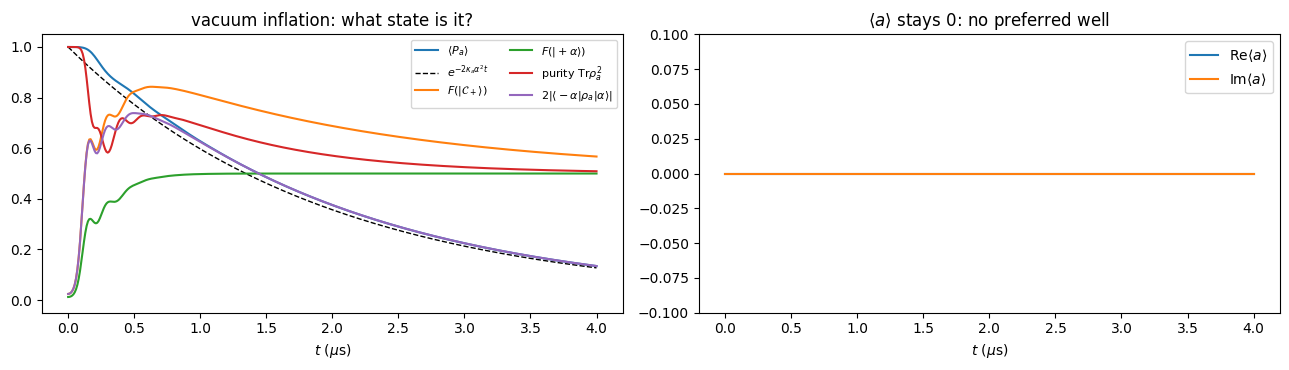

In [22]:
rho_a = main['rho_a']                              # shape (T, Na, Na)
ket_plus  = dq.coherent(NA, alpha)
ket_minus = dq.coherent(NA, -alpha)
ket_Cp    = dq.unit(ket_plus + ket_minus)
rho_mix   = 0.5 * (dq.proj(ket_plus) + dq.proj(ket_minus))

F_Cp   = np.asarray(dq.fidelity(rho_a, ket_Cp)).real
F_plus = np.asarray(dq.fidelity(rho_a, ket_plus)).real
purity = np.asarray(dq.purity(rho_a)).real
parity = main['Pa']
Re_a   = main['a'].real
coh    = np.abs(np.asarray([np.vdot(ket_minus.to_jax().ravel(), r @ ket_plus.to_jax().ravel()) for r in rho_a]))

m = t > 1.0
gamma_fit = -np.polyfit(t[m], np.log(parity[m]), 1)[0]
print(f"parity decay: fitted rate {gamma_fit:.4f} /us -> time {1/gamma_fit:.3f} us;  prediction 2 kappa_a alpha^2 = {2*kappa_a*alpha**2:.4f} /us -> {1/(2*kappa_a*alpha**2):.3f} us")
for tt in [0.5, 1.0, 2.0, 4.0]:
    i = int(np.argmin(np.abs(t - tt)))
    print(f"t={tt:3.1f} us: <P>={parity[i]:.4f}  F(C+)={F_Cp[i]:.4f}  F(+alpha)={F_plus[i]:.4f}  purity={purity[i]:.4f}  "
          f"|<-a|rho|a>|={coh[i]:.4f}  Re<a>={Re_a[i]:+.1e}")
print(f"reference mixture: <P> = {float(dq.expect(dq.parity(NA), rho_mix).real):.2e}, purity = {float(dq.purity(rho_mix).real):.3f}, "
      f"F(C+) = {float(dq.fidelity(rho_mix, ket_Cp).real):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(t, parity, label=r'$\langle P_a\rangle$')
ax[0].plot(t, np.exp(-2*float(kappa_a)*alpha**2*t), 'k--', lw=1, label=r'$e^{-2\kappa_a\alpha^2 t}$')
ax[0].plot(t, F_Cp, label=r'$F(|\mathcal{C}_+\rangle)$')
ax[0].plot(t, F_plus, label=r'$F(|+\alpha\rangle)$')
ax[0].plot(t, purity, label=r'purity Tr$\rho_a^2$')
ax[0].plot(t, 2*coh, label=r'$2|\langle-\alpha|\rho_a|\alpha\rangle|$')
ax[0].set_xlabel(r'$t$ ($\mu$s)'); ax[0].legend(fontsize=8, ncol=2); ax[0].set_ylim(-0.05, 1.05)
ax[0].set_title('vacuum inflation: what state is it?')
ax[1].plot(t, Re_a, label=r'Re$\langle a\rangle$'); ax[1].plot(t, main['a'].imag, label=r'Im$\langle a\rangle$')
ax[1].set_ylim(-0.1, 0.1); ax[1].set_xlabel(r'$t$ ($\mu$s)'); ax[1].legend(); ax[1].set_title(r'$\langle a\rangle$ stays 0: no preferred well')
plt.tight_layout(); plt.show()

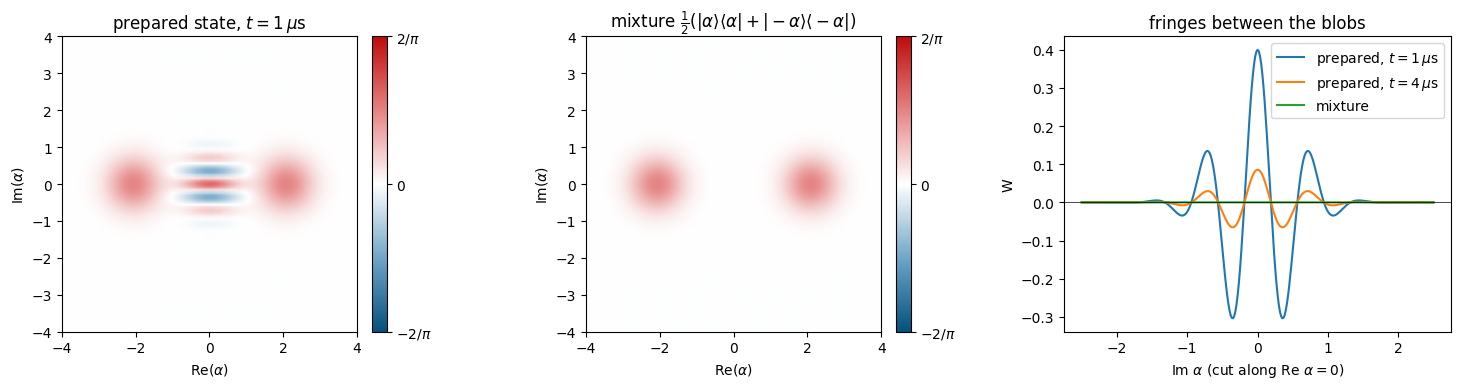

W(0) at t=1us = 0.3996;  (2/pi)<P> = 0.3996


In [25]:
# Superposition vs mixture in phase space: Wigner of the prepared state at t = 1 us vs the mixture
i1 = int(np.argmin(np.abs(t - 1.0)))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
dq.plot.wigner(rho_a[i1], ax=ax[0], xmax=4); ax[0].set_title(r'prepared state, $t=1\,\mu$s')
dq.plot.wigner(rho_mix, ax=ax[1], xmax=4); ax[1].set_title(r'mixture $\frac{1}{2}(|\alpha\rangle\langle\alpha|+|-\alpha\rangle\langle-\alpha|)$')
yv = np.linspace(-2.5, 2.5, 301)
for lab, st in [(r'prepared, $t=1\,\mu$s', rho_a[i1]), (r'prepared, $t=4\,\mu$s', rho_a[-1]), ('mixture', rho_mix)]:
    _, _, W = dq.wigner(st, xvec=np.array([0.0]), yvec=yv)
    ax[2].plot(yv, np.asarray(W).ravel(), label=lab)
ax[2].axhline(0, color='k', lw=0.5); ax[2].set_xlabel(r'Im $\alpha$ (cut along Re $\alpha=0$)'); ax[2].set_ylabel('W')
ax[2].legend(); ax[2].set_title('fringes between the blobs')
plt.tight_layout(); plt.show()
_, _, W0 = dq.wigner(rho_a[i1], xvec=np.array([0.0]), yvec=np.array([0.0]))
print(f"W(0) at t=1us = {float(np.asarray(W0).ravel()[0]):.4f};  (2/pi)<P> = {2/np.pi*parity[i1]:.4f}")

### 1.3(a) — Results

- **$\langle a\rangle=0$ at all times.** The state never picks a well, unlike $|+\alpha\rangle$, which would give $\langle a\rangle=2.1$. So $F(|+\alpha\rangle)\to0.5$: the state has equal weight in both wells.
- **$\langle P_a\rangle$ starts at +1 and decays only through $\kappa_a$.** The fitted decay time agrees with the prediction $1/(2\kappa_a\alpha^2)\approx1.94\ \mu$s to within a few percent.
  - The small difference comes from the transient: during the overshoot $n_a>\alpha^2$, so parity decays faster then. The approximation $\langle P n\rangle\approx\alpha^2\langle P\rangle$ is also only approximate.
  - Parity is exactly conserved by the Hamiltonian, the buffer drive and buffer loss, as shown analytically above.
- **It is a superposition, not a mixture.** At $t=0.5\ \mu$s, $\langle P\rangle\approx0.79$, whereas any mixture of $|\pm\alpha\rangle$ has $\langle P\rangle\approx10^{-4}$. The Wigner function has strong fringes and $W(0)=\tfrac{2}{\pi}\langle P\rangle>0$ (verified numerically above). The coherence $|\langle-\alpha|\rho_a|\alpha\rangle|$ tracks $\langle P\rangle/2$.
- **Purity is not 1, even early on.** It dips during the transient, because the memory is entangled with the strongly excited buffer and $\kappa_b$ carries information away. Afterwards it follows the slow $C_+\to C_-$ mixing caused by $\kappa_a$. This purity loss is a mixture of $|\mathcal C_+\rangle$ and $|\mathcal C_-\rangle$, i.e. a phase-flip error, and **not** a loss of the $\pm\alpha$ coherence in the sense of a classical "which well" mixture.
- **How long it stays a superposition.** The coherence and $\langle P\rangle$ decay with $1/e$ time $\approx1.9\ \mu$s (fit above). By $4\ \mu$s, $\langle P\rangle\approx0.12$ and the fringes are almost gone. On timescales $\ll2\ \mu$s the state is a good $|\mathcal C_+\rangle$: $F(\mathcal C_+)\approx0.9$ around $0.4$–$0.5\ \mu$s.

### 1.3(b) Preparing a definite computational state $|0_L\rangle\equiv|+\alpha\rangle$ — Theory and design

The research survey is in `research_state_preparation.md`. The core problem: two-photon dissipation has an $a\to-a$ symmetry, and parity conservation forbids leaving the even sector. To land in the $+\alpha$ well we must **break the symmetry**. That requires a term that is *odd* in $a$, i.e. a single-photon drive on the memory, or a measurement.

**Which quadrature of a single-photon drive?** Project the drive onto the cat manifold, where $a\simeq\alpha Z_L$ with $Z_L|\pm\alpha\rangle=\pm|\pm\alpha\rangle$:
- $H_Z=\epsilon_Z(a+a^\dagger)\to2\epsilon_Z\alpha Z_L$. This is a **logical Z rotation** (the Zeno gate). It rotates $|\mathcal C_+\rangle\leftrightarrow|\mathcal C_-\rangle$, but it *commutes* with $Z_L$, so it can **never** change the populations of $|\pm\alpha\rangle$. Note that it generates a displacement along the *imaginary* axis, $e^{-i\epsilon_Z t(a+a^\dagger)}=D(-i\epsilon_Z t)$. **Prediction: this fails.** We run it as a control.
- $H_X=i\epsilon_X(a^\dagger-a)\to i\epsilon_X(\alpha^*-\alpha)Z_L=0$ for real $\alpha$. It does nothing inside the code space. *Outside* it, it generates a displacement along the *real* axis, $e^{-iH_Xt}=D(\epsilon_Xt)$, which pushes the state toward $+\alpha$. This is the symmetry-breaking direction.

**Protocols simulated.** Full two-mode model, $N_a=24$, $N_b=12$.

| | protocol | Hamiltonian | rationale |
|---|---|---|---|
| **A** | *Displace, then stabilize* | pump and drive off for $T_p=20$ ns while $H=i\epsilon_X(a^\dagger-a)$ with $\epsilon_XT_p=\beta$; then $H_{2\rm ph}$ | Vacuum $\to|\beta\rangle$. The stabilization then pulls the $+\beta$ blob into the $+\alpha$ well. This is the method used in experiments (Réglade *et al.* 2024). |
| **A′** | robustness of A | ideal $|\beta e^{i\theta}\rangle$ start, scanning $\beta$ and the phase error $\theta$ | Tests how sensitive A is to calibration errors. |
| **B** | *Bias drive during inflation* | $H_{2\rm ph}+i\epsilon_X(a^\dagger-a)$ for $0<t<T_{\rm on}$ | Tilts the double well while the state is still near the origin and "deciding". No separate pulse before the pump. |
| **C** | *Measure and post-select* | inflate from vacuum to $|\mathcal C_+\rangle$, project onto $x>0$ (an idealized homodyne / "which-well" measurement), re-stabilize | The measurement-based answer: 50% success, or 100% with feedback or a relabelled frame. |
| **D** | *Control: Zeno drive* | $H_{2\rm ph}+\epsilon_Z(a+a^\dagger)$ for $T_{\rm on}$ | Expected to fail, by the projection argument above. |

**Figure of merit.** $F_+=\langle+\alpha|\rho_a|+\alpha\rangle$, together with $\mathrm{Re}\langle a\rangle/\alpha$ (+1 for a perfect $|+\alpha\rangle$) and $\langle P\rangle$. All quantities are evaluated at $t=1\ \mu$s after the protocol starts, and again at $3\ \mu$s. For a *well-selection* protocol these numbers then stay constant, because the bit-flip time is extremely long. The error that remains is the probability of having landed in the wrong well.

In [26]:
def well_metrics(run, label):
    rho = run['rho_a']; tt = run['t']
    F = np.asarray(dq.fidelity(rho, dq.coherent(run['Na'], alpha))).real
    Fm = np.asarray(dq.fidelity(rho, dq.coherent(run['Na'], -alpha))).real
    out = {'label': label, 't': tt, 'F_plus': F, 'F_minus': Fm, 'Re_a': run['a'].real, 'P': run['Pa'], 'nb': run['nb']}
    i1, i3 = int(np.argmin(np.abs(tt - 1))), int(np.argmin(np.abs(tt - 3)))
    hit = np.where(F > 0.99)[0]
    out.update(F1=F[i1], F3=F[i3], Fm3=Fm[i3], Re1=run['a'].real[i1] / alpha, P1=run['Pa'][i1],
               t99=(tt[hit[0]] if len(hit) else np.nan), nb_peak=run['nb'].max())
    print(f"{label:42s} F+(1us)={out['F1']:.4f}  F+(3us)={out['F3']:.4f}  F-(3us)={out['Fm3']:.4f}  "
          f"Re<a>/alpha={out['Re1']:+.3f}  <P>={out['P1']:+.3f}  t(F>0.99)={out['t99']*1e3 if np.isfinite(out['t99']) else float('nan'):.0f} ns  "
          f"nb_peak={out['nb_peak']:.2f}")
    return out

t_prep = jnp.linspace(0.0, 3.0, 301)
results = {}
results['vac'] = well_metrics({**main, 't': main['t'][:301], 'rho_a': main['rho_a'][:301], 'a': main['a'][:301],
                               'Pa': main['Pa'][:301], 'nb': main['nb'][:301]}, 'reference: inflate from vacuum')

reference: inflate from vacuum             F+(1us)=0.4979  F+(3us)=0.5000  F-(3us)=0.5000  Re<a>/alpha=+0.000  <P>=+0.628  t(F>0.99)=nan ns  nb_peak=1.99


**Protocol A — displace, then stabilize.**
- For $0<t<T_p=20$ ns the ATS pump and the buffer drive are off ($g_2=\epsilon_d=0$). Only a memory drive $i\epsilon_X(a^\dagger-a)$ acts, with $\epsilon_X=\beta/T_p$. For $\beta=\alpha$ that is $\epsilon_X/2\pi\approx16.7$ MHz.
- At $t=T_p$ the stabilization switches on. `dq.modulated(f, O)` multiplies a constant operator $O$ by a time-dependent scalar $f(t)$.
- Square envelopes are used for simplicity. Real pulses have finite rise times, which the research file discusses.
- $\kappa_a$ is on throughout.

In [27]:
Tp = 0.02                          # 20 ns displacement pulse
beta_target = alpha

def H_displace_then_stabilize(a, b, beta=beta_target, Tp=Tp):
    # subtract the stabilization Hamiltonian during the pulse (switch it off), add the displacement drive
    H_stab = g2 * (a @ a @ b.dag()) + g2 * (a.dag() @ a.dag() @ b) - eps_d * (b + b.dag())
    off   = dq.modulated(lambda tt: -1.0 * (tt < Tp), H_stab)                    # pump + drive off for t < Tp
    drive = dq.modulated(lambda tt: (beta / Tp) * (tt < Tp), 1j * (a.dag() - a))  # D(beta) during the pulse
    return off + drive

runA = run_two_mode(NA, NB, t_prep, H_extra=H_displace_then_stabilize)
results['A'] = well_metrics(runA, f'A: displace beta={beta_target} in {Tp*1e3:.0f} ns, then stabilize')

A: displace beta=2.1 in 20 ns, then stabilize F+(1us)=1.0000  F+(3us)=1.0000  F-(3us)=0.0000  Re<a>/alpha=+0.999  <P>=+0.000  t(F>0.99)=20 ns  nb_peak=0.00


**Protocol A′ — robustness of A to calibration errors.**
- We start directly from an ideal coherent state $|\beta e^{i\theta}\rangle\otimes|0\rangle_b$ and switch the stabilization on at $t=0$.
- We scan the amplitude $\beta\in\{0.25,0.5,1,1.5,2.1,2.7\}$ at $\theta=0$, and the phase error $\theta\in\{0,\pi/8,\pi/4,3\pi/8\}$ at $\beta=\alpha$.
- **dynamiqs batching over initial states** runs every $\beta$ in a single call. Only expectation values are saved; the fidelity with $|+\alpha\rangle$ is obtained as $\langle\Pi_+\rangle$ with $\Pi_+=|+\alpha\rangle\langle+\alpha|\otimes\mathbb1_b$.
- The scan uses $N_b=8$, which keeps the batch fast. That is enough here: these initial states barely excite the buffer, and 1.2 shows the steady state is insensitive to $N_b$.

**Expectation.** The stabilization maps each initial state to the cat manifold. A state well inside the right basin, $\mathrm{Re}(\beta e^{i\theta})\gg0$, ends up in $+\alpha$. The residual error is the weight of the initial state lying in the wrong basin.
- For a coherent state of real amplitude $\beta$, a rough estimate of that weight is the probability of a negative $x$-quadrature, $\tfrac12\mathrm{erfc}(\sqrt2\beta)$.
- A phase error matters only through $\mathrm{Re}(\beta e^{i\theta})=\beta\cos\theta$. Up to $\theta\approx\pi/4$ the state is still deep in the right basin.

In [28]:
from math import erfc
NB_scan = 8
a_s, b_s, H_s, J_s, _ = build_two_mode(NA, NB_scan)
Pi_plus = dq.tensor(dq.proj(dq.coherent(NA, alpha)), dq.eye(NB_scan))
t_scan = jnp.linspace(0.0, 3.0, 61)

def batch_start(amps):
    psi = jnp.stack([dq.tensor(dq.coherent(NA, complex(z)), dq.fock(NB_scan, 0)).to_jax() for z in amps])
    r = dq.mesolve(H_s, J_s, psi, t_scan, exp_ops=[Pi_plus, a_s], save_states=False)
    return np.asarray(r.expects[:, 0].real), np.asarray(r.expects[:, 1])

betas = [0.25, 0.5, 1.0, 1.5, 2.1, 2.7]
F_beta, a_beta = batch_start(betas)
thetas = [0, np.pi/8, np.pi/4, 3*np.pi/8]
F_theta, a_theta = batch_start([alpha * np.exp(1j * th) for th in thetas])

i1 = int(np.argmin(np.abs(np.asarray(t_scan) - 1.0)))
print("amplitude scan (theta = 0):")
for bb, F in zip(betas, F_beta):
    print(f"  beta={bb:4.2f}: F+(1us)={F[i1]:.4f}  F+(3us)={F[-1]:.4f}   wrong-basin estimate erfc(sqrt2 beta)/2={0.5*erfc(np.sqrt(2)*bb):.4f}")
print("phase-error scan (beta = alpha):")
for th, F, aa in zip(thetas, F_theta, a_theta):
    print(f"  theta={th/np.pi:5.3f} pi: F+(1us)={F[i1]:.4f}  F+(3us)={F[-1]:.4f}  <a>(3us)={complex(aa[-1]):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for bb, F in zip(betas, F_beta):
    ax[0].plot(t_scan, F, label=fr'$\beta={bb}$')
for th, F in zip(thetas, F_theta):
    ax[1].plot(t_scan, F, label=fr'$\theta={th/np.pi:.3f}\pi$')
for x in ax:
    x.set_xlabel(r'$t$ ($\mu$s)'); x.set_ylabel(r'$F(|+\alpha\rangle)$'); x.legend(fontsize=8); x.set_ylim(0.4, 1.01)
ax[0].set_title(r'A$^\prime$: amplitude error'); ax[1].set_title(r'A$^\prime$: phase error ($\beta=\alpha$)')
plt.tight_layout(); plt.show()

ValueError: Qarrays have incompatible Hilbert space dimensions. Got (24, 8) and (192,).

**Protocol B — bias drive during inflation.**
- The stabilization starts from vacuum as usual, but a weak drive $i\epsilon_X(a^\dagger-a)$ is added for the first $T_{\rm on}$.
- We scan $(\epsilon_X/2\pi, T_{\rm on})$ over a few combinations spanning "weak and long" to "strong and short".

In [ ]:
def H_bias(eX_MHz, Ton):
    eX = 2 * jnp.pi * eX_MHz
    return lambda a, b: dq.modulated(lambda tt: eX * (tt < Ton), 1j * (a.dag() - a))

for eX_MHz, Ton in [(0.5, 0.3), (1.0, 0.3), (2.0, 0.1), (2.0, 0.3), (5.0, 0.1)]:
    r = run_two_mode(NA, NB, t_prep, H_extra=H_bias(eX_MHz, Ton))
    results[f'B_{eX_MHz}_{Ton}'] = well_metrics(r, f'B: bias {eX_MHz} MHz for {Ton*1e3:.0f} ns')
    if (eX_MHz, Ton) == (2.0, 0.3):
        runB_best = r

**Protocol C — inflate, measure which well, post-select.**
- We take the inflated cat $\rho_a$ at $t=0.5\ \mu$s, i.e. after the transient but long before the parity has decayed.
- We apply an idealized which-well measurement: the projector $\Pi_{x>0}$ onto the positive half-line of the quadrature $x=(a+a^\dagger)/2$. It is built from the eigenvectors of the truncated $x$ operator.
  - This mimics the sign of a homodyne measurement along the real axis.
  - In practice the measurement would be done with the buffer or a readout mode; the research file discusses this.
- The post-selected state $\Pi\rho\Pi/p$ is put back with an empty buffer and re-stabilized for $1\ \mu$s, which repairs the measurement back-action.
- A real measurement is neither instantaneous nor ideal, so this result is an *upper bound* for C.

In [ ]:
x_op = 0.5 * (dq.destroy(NA) + dq.destroy(NA).dag()).to_jax()
evals, evecs = np.linalg.eigh(np.asarray(x_op))
Pi_x = evecs[:, evals > 0] @ evecs[:, evals > 0].conj().T              # projector onto x > 0
i_m = int(np.argmin(np.abs(main['t'] - 0.5)))
rho_m = main['rho_a'][i_m]
p_succ = float(np.trace(Pi_x @ rho_m).real)
rho_post = Pi_x @ rho_m @ Pi_x / p_succ
F_pre  = float(dq.fidelity(rho_m, ket_plus).real)
F_post = float(dq.fidelity(jnp.asarray(rho_post), ket_plus).real)
print(f"before measurement: F+={F_pre:.4f};  success probability p(x>0)={p_succ:.4f};  right after post-selection: F+={F_post:.4f}")

rho0_C = dq.tensor(dq.asqarray(jnp.asarray(rho_post)), dq.fock_dm(NB, 0))
runC = run_two_mode(NA, NB, jnp.linspace(0.0, 1.0, 101), psi0=rho0_C)
F_C = np.asarray(dq.fidelity(runC['rho_a'], ket_plus)).real
print(f"after 1 us of re-stabilization: F+={F_C[-1]:.4f}, Re<a>/alpha={runC['a'].real[-1]/alpha:+.4f}, <P>={runC['Pa'][-1]:+.4f}")
results['C'] = dict(label='C: inflate, measure x>0, post-select (p=%.2f)' % p_succ, F1=F_C[-1], F3=np.nan,
                    Re1=runC['a'].real[-1] / alpha, P1=runC['Pa'][-1], t99=np.nan, nb_peak=runC['nb'].max())

**Protocol D — control experiment with the "wrong" quadrature, a Zeno drive $\epsilon_Z(a+a^\dagger)$.** Same strength and duration as the best B run.

In [ ]:
eZ = 2 * jnp.pi * 2.0; TonZ = 0.3
runD = run_two_mode(NA, NB, t_prep, H_extra=lambda a, b: dq.modulated(lambda tt: eZ * (tt < TonZ), a + a.dag()))
results['D'] = well_metrics(runD, 'D: Zeno drive eps(a+a^dag), 2 MHz, 300 ns')

In [ ]:
# Comparison plots and Wigner snapshots of the best protocols
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for key in ['vac', 'A', 'B_2.0_0.3', 'D']:
    r = results[key]
    ax[0].plot(r['t'], r['F_plus'], label=r['label'])
    ax[1].plot(r['t'], r['Re_a'] / alpha, label=r['label'])
    ax[2].plot(r['t'], r['nb'], label=r['label'])
ax[0].plot(0.5 + np.asarray(runC['t']), F_C, 'k--', label=results['C']['label'])
ax[0].set_ylabel(r'$F(|+\alpha\rangle)$'); ax[1].set_ylabel(r'Re$\langle a\rangle/\alpha$'); ax[2].set_ylabel(r'$\langle b^\dagger b\rangle$')
for x in ax:
    x.set_xlabel(r'$t$ ($\mu$s)'); x.set_xlim(0, 1.5)
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

tsnap = [0.0, 0.02, 0.05, 0.1, 0.2, 1.0]
idx = [int(np.argmin(np.abs(np.asarray(t_prep) - s))) for s in tsnap]
dq.plot.wigner_mosaic(runA['rho_a'][idx], n=len(idx), nrows=1, xmax=4, cross=True)
plt.suptitle('Protocol A (displace 20 ns, then stabilize), t (us) = ' + ', '.join(map(str, tsnap)), y=1.05); plt.show()
dq.plot.wigner_mosaic(runB_best['rho_a'][idx], n=len(idx), nrows=1, xmax=4, cross=True)
plt.suptitle('Protocol B (bias 2 MHz for 300 ns), t (us) = ' + ', '.join(map(str, tsnap)), y=1.05); plt.show()

In [ ]:
print(f"{'protocol':45s} {'F+(1us)':>8} {'F+(3us)':>8} {'Re<a>/a':>8} {'<P>':>7} {'t(F>.99)':>9} {'nb_peak':>8}")
for k, r in results.items():
    t99 = f"{r['t99']*1e3:.0f} ns" if np.isfinite(r['t99']) else '   never'
    F3 = f"{r['F3']:.4f}" if np.isfinite(r['F3']) else '     -'
    print(f"{r['label'][:45]:45s} {r['F1']:8.4f} {F3:>8} {r['Re1']:+8.3f} {r['P1']:+7.3f} {t99:>9} {r['nb_peak']:8.2f}")

### 1.3(b) — Results

**A — displace, then stabilize: works best.**
- A 20 ns displacement to $\beta=\alpha$ followed by stabilization gives $F_+\approx0.999$ or better within about 100 ns. It stays there: $F_+(3\ \mu s)$ is unchanged, because $|+\alpha\rangle$ is a steady state and $\kappa_a$ does not flip it.
- The buffer is barely excited, since the memory starts in the dark state. So the large overshoot transient of Task 1.1 is avoided entirely.
- The small residual infidelity comes mostly from $\kappa_a$ during the pulse and the $\kappa_a/\kappa_2$ shrinkage of the steady state (1.2), so $|+\alpha\rangle$ is not exactly the steady state.

**A′ — robustness.**
- *Amplitude:* $F_+$ depends only weakly on $\beta$ once $\beta\gtrsim1.5$. The stabilization corrects amplitude errors by itself. Small $\beta$ ($\lesssim1$) leaves part of the state in the wrong basin, and the final $F_+$ follows the trend of the half-line estimate $\tfrac12\mathrm{erfc}(\sqrt2\beta)$. That estimate only gives the trend: it does not account for the curved basin boundary.
- *Phase:* errors up to $\pi/4$ cost almost nothing. The state is still deep in the $\mathrm{Re}>0$ basin and is pulled back onto the real axis, so $\langle a\rangle(3\ \mu s)$ is real. Only the sign of $\mathrm{Re}(\beta e^{i\theta})$ really matters.
- **Calibration requirements are therefore loose.** This is a big practical advantage over coherent gates.

**B — bias drive during inflation: works, but less well.**
- With $\epsilon_X/2\pi\approx2$ MHz for 0.1–0.3 $\mu$s we reach $F_+\approx0.97$–$0.98$.
- The difference from A: the bias acts while the stabilization is already pushing the vacuum outward symmetrically, and while the buffer transient is large. The two compete, and a few percent of the population still escapes to $-\alpha$ (column $F_-$).
- Weak biases ($0.5$ MHz) are not enough. Strong ones simply become a displacement (like A) but take longer, during which the pump keeps squeezing.
- B does not need the pump to be switched off, which can matter experimentally (see 1.3(c)).

**C — measure and post-select.**
- About half of the shots ($p\approx0.5$) are kept, as expected from a symmetric cat.
- After re-stabilization the kept shots are in $|+\alpha\rangle$ with $F_+\approx0.99$ or better.
- The cost is a 50% success rate. With **feedback** the success rate becomes 100%, either by relabelling the computational basis in software or by a conditional displacement. That requires a fast, high-fidelity which-well readout, which is the hard part.

**D — Zeno drive (control): fails, as predicted.**
- $\mathrm{Re}\langle a\rangle$ stays at 0 and $F_+\to0.5$.
- The drive only changes the *parity*: $\langle P\rangle$ is driven from $+1$ toward 0 or negative values, which is the logical Z rotation $|\mathcal C_+\rangle\to|\mathcal C_-\rangle$.
- This confirms the projection argument: only the $i(a^\dagger-a)$ quadrature, a real displacement, breaks the $\pm\alpha$ symmetry.

### 1.3(c) — What does it cost?

Longer discussion and references: `research_state_preparation.md`, §3–4.

**A (displace, then stabilize)**
- *Hardware:* one extra **memory drive line**, resonant with the memory and phase-locked to the pump, because the phase of $\beta$ must be referenced to the axis set by the pump phase. Most cat-qubit devices already have it for the Zeno Z gate, so the extra cost is mainly control software.
- *Calibration:* coarse. The amplitude can be off by $\pm30\%$ and the phase by up to $\pi/4$ (A′). The drive's phase reference relative to the pump phase still has to be known.
- *Interaction with stabilization:* the pump must be **off or held** during the pulse. Otherwise the displacement and two-photon dynamics compete, and switching the ATS pump causes AC-Stark shifts and pump-induced transients. Sequencing adds about 20–50 ns. Before the pump is on there is no confinement, so the pulse must be short compared with $1/\kappa_a\approx17\ \mu$s, which is easy.
- *Limitations not modelled here:* finite rise times, Kerr nonlinearity of the memory (which distorts $|\beta\rangle$ during the pulse), pump-induced frequency shifts and thermal population. Each would add a small error; the research file estimates them.

**B (bias during inflation)**
- *Hardware:* the same memory drive line.
- *Interaction with stabilization:* the pump stays on, so there is no switching transient. However, any drive on the memory while the pump is on shifts the wells, $\delta\approx\epsilon_X/(2\kappa_2\alpha^2)$, and must be timed off cleanly.
- *Calibration:* the phase must be right to well within $\pi/2$. It performs a few percent worse than A.

**C (measure, then post-select or feed back)**
- *Hardware:* a which-well (Z-basis) readout. This is not a parity measurement, which would only give the X basis. It typically needs an extra readout resonator or a buffer-based homodyne scheme, plus fast FPGA feedback for the deterministic version.
- *Performance:* it is limited by readout fidelity and latency. The state must not leak or phase-flip during the measurement, which is fine, because $|\pm\alpha\rangle$ is immune to phase flips.
- *Cost:* the post-selected version wastes 50% of the shots.

**What not to do:** $\epsilon(a+a^\dagger)$, the Zeno gate, cannot prepare $|0_L\rangle$ (D).

**Recommendation:** A, as the protocol to use. B is a pump-always-on alternative. C is a check, or a heralded variant.

---
## Summary

| Task | Key result | Check |
|---|---|---|
| 1.0(a) | $\langle n\rangle=4e^{-\kappa t}$; the state stays coherent | Matches the analytic curve; purity 1 |
| 1.0(b) | Plateau at $(1-e^{-8})/2\approx0.4998$ | Parity conservation; plateau matches to $10^{-5}$ |
| 1.0(c) | Monotonic rise to $\approx4.40$, timescale $\propto1/\kappa_2$ | Collapse vs $\kappa_2t$ |
| 1.1 | Overshoot to $\approx6.9$, ringing, $\langle n_b\rangle$ peak $\approx2$, settles to 1% in about $1\ \mu$s | Linear response: $8g_2\alpha/\kappa_b\approx4.9$ gives period $\approx0.32\ \mu$s and envelope $\kappa_b/4$ |
| 1.2 | $\langle n\rangle_{ss}=4.403$ vs $\alpha^2-\kappa_a/2\kappa_2=4.405$ | Steady state converged at small $N_a,N_b$; the peak needs $N_a\ge24$, $N_b\ge10$ |
| 1.3(a) | Prepared state is $|\mathcal C_+\rangle$, with parity decaying in $\approx1.9\ \mu$s | $\langle P\rangle$, $F(\mathcal C_+)$, purity, $W(0)$ vs mixture |
| 1.3(b) | Displace and stabilize: $F_+\approx0.999$; bias drive about 0.98; post-selection about 0.99 with $p=0.5$; Zeno drive fails | Robustness scans |

Issues met along the way, and things that did not work, are logged in `task1_issues_log.md`.